# Ширины слоёв по эффективному рангу: ResNet-18 на CIFAR-10

**Что внутри.** Проверяется, годится ли эффективный ранг (erank) активаций как правило выбора ширин слоёв — простой
поиск архитектуры — по сравнению с равномерным сужением и классическими критериями структурного прунинга. ResNet-18
обучается на CIFAR-10 полным рецептом (30 эпох, 3 сида); сужаются внутренние ширины восьми блоков (выход первой
свёртки блока: его читает только вторая свёртка того же блока). Все пять шагов задания выполняются здесь же, весь
код внутри ноутбука, числа в выводах считаются из его прогонов.

erank слоя: собственные числа $\lambda_i$ ковариации каналов (каждая позиция каждой картинки — отдельное наблюдение),
$p_i=\lambda_i/\sum_j\lambda_j$, $\mathrm{erank}=\exp\left(-\sum_i p_i\ln p_i\right)$ — erank (λ), основное правило,
как в основной серии. erank по σ — определение Roy & Vetterli (2007): $p_i=\sigma_i/\sum_j\sigma_j$,
$\sigma_i=\sqrt{\lambda_i}$ — сингулярные числа центрированной матрицы активаций; здесь это отдельная мера (шаги 2 и 3).

| Шаг | Что считается | Графики |
|---|---|---|
| 1 | 3 полные сети; erank 17 слоёв после обучения, по эпохам и у необученной сети | кривые обучения; erank по слоям; erank по эпохам |
| 2 | 6 мер спектра, 4 точки замера, erank одной картинки; сколько каналов нужно блоку (L1-срез, PCA) | чувствительность блоков; Spearman по мерам; erank и потребность |
| 3 | ширины 9 методов при потолке параметров и 8 — при потолке MACs (FLOPs ≈ 2·MACs), обучение с нуля; low-rank conv2 (PCA, SVD) | точность–размер; Δ к uniform; MACs; ширины; регрессия |
| 4 | срез обученной базы (L1, HRank, случайно) → BN → 10 эпох дообучения против тех же ширин с нуля | точность до и после дообучения |
| 5 | (a) erank → ширины → обучение с нуля, 4 раунда при 25% параметров; (b) 50% → 25% → 10% со срезом и дообучением | ширины и точность по раундам |
| время | параметры, MACs, время инференса CPU и GPU | точность–время |
| Итог | разница каждого метода с uniform, парная по сиду (t95, n), и вывод из чисел шагов 2–5 | таблица |

**Время.** Полный прогон — около 4,5 ч на одном GPU класса RTX 5070 Ti (≈125 обучений с нуля по 30 эпох и ≈70
дообучений). Результаты дописываются построчно в `runs/02_resnet18.jsonl`, веса баз и сетей итераций — в
`runs/ckpt/02_resnet18/`; повторный запуск продолжает с места остановки: законченные обучения и замеры берутся из
файла, прерванное обучение начинается заново.

**Быстрая проверка.** `QUICK = True` в первой ячейке кода: 1 сид, 1 эпоха, 2048 train-картинок, несколько минут;
числа тогда ничего не значат, проверяется только, что работает каждая ячейка.

**Данные.** CIFAR-10 в `data/cifar-10-batches-py/` рядом с ноутбуком или в `../data/`; ничего не скачивается
(`DOWNLOAD = False`). Переключатели `ARCH = "resnet20"` и `DATASET = "cifar100"` меняют сеть, рецепт и бюджеты.

In [1]:
QUICK = False  # True — быстрая проверка всех ячеек (1 сид, 1 эпоха, подвыборка)
NB_NAME = "02_resnet18"
ARCH = "resnet18"    # "resnet18" | "resnet20"
DATASET = "cifar10"  # "cifar10" | "cifar100"
DOWNLOAD = False     # True lets torchvision download CIFAR when no local copy is found

import platform

import torch
import torchvision

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEEDS = [0, 1, 2]
# per network: epochs and peak lr from scratch (main series); budgets that the floor of 8 channels per block allows
RECIPES = {
    "resnet18": {"epochs": 30, "lr": 0.1, "param_budgets": [0.25, 0.1], "mac_budgets": [0.25, 0.1],
                 "iter_budget": 0.25, "progressive": [0.5, 0.25, 0.1]},
    "resnet20": {"epochs": 40, "lr": 0.2, "param_budgets": [0.5, 0.25], "mac_budgets": [0.5],
                 "iter_budget": 0.25, "progressive": [0.5, 0.25]},
}
EPOCHS, LR = RECIPES[ARCH]["epochs"], RECIPES[ARCH]["lr"]  # SGD + one-cycle; wd 5e-4, batch 256 = train() defaults
FT_EPOCHS, FT_LR = 10, 0.01              # fine-tuning after a cut
LOWRANK_FT_EPOCHS = FT_EPOCHS // 2       # low-rank conv2: 5 epochs, as in the main series
PARAM_BUDGETS = RECIPES[ARCH]["param_budgets"]  # fractions of the full network's parameters
MAC_BUDGETS = RECIPES[ARCH]["mac_budgets"]      # fractions of its multiply-adds per picture
ITER_BUDGET, ITER_ROUNDS = RECIPES[ARCH]["iter_budget"], 4  # step 5a: fixed budget (params)
PROGRESSIVE = RECIPES[ARCH]["progressive"]                   # step 5b: decreasing budgets (params)
PARAM_METHODS = ["uniform", "random", "erank", "taylor_global", "gamma_global", "slimming", "l1_need",
                 "erank_cost", "cost_only"]
MAC_METHODS = ["uniform", "random", "erank", "erank_sv", "taylor_global", "gamma_global", "slimming", "l1_need"]
FT_METHODS, FT_SELECT = ["uniform", "erank"], ["l1", "hrank", "random"]
SLIM_L1 = 1e-3                   # Network Slimming: + SLIM_L1 * sum |gamma| of the inner BatchNorms
BN_N = 10_000                    # BatchNorm recalibration on x_train[:BN_N]
PCA_ROWS = (10_000, 12_000)      # sensitivity: PCA basis from these train pictures
PROBE_N = 1000                   # erank after every epoch on x_val[:PROBE_N]
PER_IMAGE_N = 500                # per-picture erank (paper variant) on x_val[:PER_IMAGE_N]


SENS_FRACTIONS = [1 / 64, 1 / 32, 1 / 16, 3 / 32, 1 / 8, 3 / 16, 1 / 4, 5 / 16, 3 / 8, 1 / 2, 5 / 8, 3 / 4,
                  13 / 16, 7 / 8, 15 / 16]  # the last three: narrow nets (ResNet-20) whose erank is ~80% of the width


SENS_DROP = 1.0                  # need = smallest k that loses at most 1 p.p. of val accuracy
LOWRANK_MULTS = [0.5, 1, 2]      # rank of conv2 = mult x erank
CPU_THREADS, LAT_REPEATS, LAT_REPEATS_B1 = 4, 30, 100
N_TRAIN = N_VAL = N_TEST = None  # None = the whole split
if QUICK:
    SEEDS = [0]
    EPOCHS = FT_EPOCHS = LOWRANK_FT_EPOCHS = 1
    N_TRAIN, N_VAL, N_TEST = 2048, 1000, 2000
    PCA_ROWS = (1024, 2048)
    SENS_FRACTIONS = [1 / 4, 1 / 2]
    ITER_ROUNDS = 2
    LAT_REPEATS = LAT_REPEATS_B1 = 3

print(f"torch {torch.__version__}, torchvision {torchvision.__version__}, Python {platform.python_version()}")
print(f"устройство: {torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU'}; QUICK = {QUICK}")
print(f"{ARCH} / {DATASET}: {EPOCHS} эпох, lr {LR}, сиды {SEEDS}")

torch 2.12.1+cu130, torchvision 0.27.1+cu130, Python 3.13.13
устройство: NVIDIA GeForce RTX 5070 Ti; QUICK = False
resnet18 / cifar10: 30 эпох, lr 0.1, сиды [0, 1, 2]


In [2]:
import matplotlib.pyplot as plt

PALETTE = {
    "uniform": "#52514e",   # reference: dark grey, dashed line
    "random": "#a3a29c",    # light grey
    "erank": "#2a78d6",     # blue
    "taylor": "#eb6834",    # orange   (taylor_global, taylor_cost, Taylor selection)
    "gamma": "#1baf7a",     # aqua     (gamma_global, gamma selection)
    "slimming": "#eda100",  # yellow
    "l1": "#e87ba4",        # magenta  (l1_need, L1 selection)
    "dnas": "#008300",      # green
    "erank_sv": "#6250d6",  # violet   (also erank variants: PR, energy99, pre-activation -> use markers)
    "cost": "#e34948",      # red      (cost_only; erank_cost = blue with a dotted line)
    "hrank": "#6250d6", "variance": "#6250d6", "teacher": "#0b0b0b",
    "pca": "#2a78d6", "svd": "#e34948",
}
MARKERS = {"uniform": "s", "random": "x", "erank": "o", "taylor": "^", "gamma": "v", "slimming": "P", "l1": "D",
           "dnas": "*", "erank_sv": "h", "cost": "X", "hrank": "p", "variance": "<", "teacher": ">",
           "erank_cost": "d", "pca": "H", "svd": "8"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110, "font.size": 10, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "lines.linewidth": 1.8, "lines.markersize": 6, "legend.frameon": False,
    "axes.facecolor": "#fcfcfb", "figure.facecolor": "#fcfcfb", "axes.edgecolor": "#8a8984",
    "text.color": "#0b0b0b", "axes.labelcolor": "#0b0b0b", "xtick.color": "#52514e", "ytick.color": "#52514e"})

## Кэш результатов

Каждый дорогой расчёт (обучение, дообучение, замер) выполняется через `cached(run_id, fn)`: готовая строка берётся
из `runs/<имя>.jsonl`, иначе считается и дописывается. Идентификатор обучения с нуля содержит сеть, данные, ширины,
сид и число эпох, поэтому одинаковые ширины обучаются один раз и используются всеми методами. Обученные базы и
сети итераций сохраняются как `state_dict`.

In [3]:
import datetime
import gc
import hashlib
import json
from pathlib import Path

RUNS = Path("runs")
RESULTS = RUNS / (f"{NB_NAME}_quick.jsonl" if QUICK else f"{NB_NAME}.jsonl")
CKPT = RUNS / (f"{NB_NAME}_quick_ckpt" if QUICK else f"ckpt/{NB_NAME}")
LOG = RUNS / (f"{NB_NAME}_quick.log" if QUICK else f"{NB_NAME}.log")


def log(msg: str, show: bool = True) -> None:
    """Print (optionally) and append a timestamped line to the log file, which a long run can be followed in."""
    if show:
        print(msg, flush=True)
    LOG.parent.mkdir(parents=True, exist_ok=True)
    with open(LOG, "a", encoding="utf-8") as f:
        f.write(f"{datetime.datetime.now():%Y-%m-%d %H:%M:%S}  {msg}\n")


def read_rows(path: Path) -> dict:
    """{run_id: row} of a results file; a later line wins, a line cut off by a crash is skipped."""
    rows = {}
    if path.exists():
        for line in path.read_text(encoding="utf-8").splitlines():
            try:
                row = json.loads(line)
            except json.JSONDecodeError:
                continue
            rows[row["run_id"]] = row
    return rows


ROWS = read_rows(RESULTS)


def store(run_id: str, row: dict) -> dict:
    row = {"run_id": run_id, **row}
    RESULTS.parent.mkdir(parents=True, exist_ok=True)
    with open(RESULTS, "a+b") as f:  # a line cut off by a crash must not swallow this one
        f.seek(0, 2)
        if f.tell():
            f.seek(-1, 2)
            if f.read(1) != b"\n":
                f.write(b"\n")
    with open(RESULTS, "a", encoding="utf-8") as f:
        f.write(json.dumps(row) + "\n")
        f.flush()
    ROWS[run_id] = json.loads(json.dumps(row))  # the same types as a row read back from the file
    return ROWS[run_id]


def cached(run_id: str, fn) -> dict:
    """The stored row of `run_id`, or row = fn() computed now and appended to the results file."""
    if run_id in ROWS:
        return ROWS[run_id]
    return store(run_id, fn())


def ckpt_path(run_id: str) -> Path:
    return CKPT / (hashlib.md5(run_id.encode()).hexdigest()[:16] + ".pt")


def cached_net(run_id: str, make):
    """(model, row) of a trained network: reloaded from its checkpoint when both exist, else make() -> (model, row),
    saved (weights first, then the row). A stored row without its weights is an error, not a silent retrain: rows
    computed from the old weights (widths, cuts, later rounds) would be mixed with a different network."""
    path = ckpt_path(run_id)
    if run_id in ROWS:
        if not path.exists():
            raise FileNotFoundError(
                f"{run_id}: строка есть в {RESULTS}, но нет весов {path}. Результаты, посчитанные на этих весах, "
                "нельзя смешивать с заново обученной сетью: верните файл весов или удалите файл результатов.")
        row = ROWS[run_id]
        model = new_model(row["inner_widths"]).to(DEVICE)
        model.load_state_dict(torch.load(path, map_location=DEVICE))
        return model.eval(), row
    model, row = make()
    path.parent.mkdir(parents=True, exist_ok=True)
    torch.save(model.state_dict(), path.with_suffix(".tmp"))
    path.with_suffix(".tmp").replace(path)
    return model.eval(), store(run_id, row)


def free() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## Код

Функции ниже перенесены из кода основной серии без изменений: меры спектра, ResNet, данные и аугментация, обучение,
пересчёт BatchNorm, замер ковариаций, подбор ширин под бюджет (`fit_budget`, `global_widths`), выбор каналов,
low-rank conv2, задержка. Из `channel_scores`, `keep_inner`, `lowrank_conv2`, `inner_means` убраны только ветки
для ViT, из `alloc_widths` — ветка DNAS, из `finetune_one` и функций анализа — чтение и запись файлов.
Новый код помечен `NEW`.

In [4]:
import math

import torch
from torch import Tensor


def _entropy_rank(weights: Tensor) -> float:
    """exp(entropy of the normalized weights). If k weights are equal and the rest are 0, this gives exactly
    k, so it reads as "how many directions really matter"; an uneven spread gives a number between 1 and k."""
    weights = weights.double().clamp_min(0)
    total = weights.sum()
    if total <= 0:
        return 0.0
    p = weights / total
    p = p[p > 0]
    return math.exp(float(-(p * p.log()).sum()))


def erank_sv(eigvals: Tensor) -> float:
    """Entropy effective rank, distribution built from singular values sigma = sqrt(lambda)."""
    return _entropy_rank(eigvals.double().clamp_min(0).sqrt())


def erank_energy(eigvals: Tensor) -> float:
    """Entropy effective rank with distribution built from lambda (= sigma^2)."""
    return _entropy_rank(eigvals)


def participation_ratio(eigvals: Tensor) -> float:
    ev = eigvals.double().clamp_min(0)
    denom = float((ev**2).sum())
    return float(ev.sum()) ** 2 / denom if denom > 0 else 0.0


def stable_rank(eigvals: Tensor) -> float:
    ev = eigvals.double().clamp_min(0)
    top = float(ev.max()) if ev.numel() else 0.0
    return float(ev.sum()) / top if top > 0 else 0.0


def energy_rank(eigvals: Tensor, threshold: float = 0.99) -> int:
    ev = eigvals.double().clamp_min(0).sort(descending=True).values
    total = float(ev.sum())
    if total <= 0:
        return 0
    cum = torch.cumsum(ev, 0) / total
    return int((cum < threshold - 1e-12).sum().item()) + 1  # -1e-12: round-off must not hide a share exactly at the threshold


def numerical_rank(eigvals: Tensor, rtol: float = 1e-6) -> int:
    sv = eigvals.double().clamp_min(0).sqrt()
    if sv.numel() == 0 or float(sv.max()) == 0:
        return 0
    return int((sv > rtol * sv.max()).sum().item())


def all_metrics(eigvals: Tensor) -> dict[str, float]:
    return {
        "erank_sv": erank_sv(eigvals),
        "erank_energy": erank_energy(eigvals),
        "participation_ratio": participation_ratio(eigvals),
        "stable_rank": stable_rank(eigvals),
        "energy90": float(energy_rank(eigvals, 0.90)),
        "energy99": float(energy_rank(eigvals, 0.99)),
        "rank": float(numerical_rank(eigvals)),
        "dim": float(eigvals.numel()),
    }

In [5]:
from torch import nn


class Block(nn.Module):
    def __init__(self, in_ch: int, inner: int, out_ch: int, stride: int):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, inner, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(inner)
        self.conv2 = nn.Conv2d(inner, out_ch, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.shortcut = nn.Identity()
        if stride != 1 or in_ch != out_ch:  # the shape changes: a 1x1 conv makes the input fit
            self.shortcut = nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, stride, bias=False), nn.BatchNorm2d(out_ch))

    def forward(self, x: torch.Tensor, acts: list | None = None) -> torch.Tensor:
        inner = torch.relu(self.bn1(self.conv1(x)))                       # (batch, inner, H, W)
        out = torch.relu(self.bn2(self.conv2(inner)) + self.shortcut(x))  # (batch, out_ch, H, W)
        if acts is not None:
            acts += [inner, out]
        return out


class ResNet(nn.Module):
    def __init__(self, stage_widths: list[int], blocks_per_stage: int, inner_widths: list[int] | None = None,
                 num_classes: int = 10):
        """inner_widths: one number per block; by default every block's inner width equals its stage width."""
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, stage_widths[0], 3, 1, 1, bias=False),
                                  nn.BatchNorm2d(stage_widths[0]), nn.ReLU())
        self.blocks = nn.ModuleList()
        prev = stage_widths[0]
        for stage, width in enumerate(stage_widths):
            for b in range(blocks_per_stage):
                stride = 2 if stage > 0 and b == 0 else 1  # every new stage halves the picture: 32 -> 16 -> 8 -> 4
                inner = inner_widths[len(self.blocks)] if inner_widths else width
                self.blocks.append(Block(prev, inner, width, stride))
                prev = width
        self.head = nn.Linear(prev, num_classes)

    def forward(self, x: torch.Tensor, acts: list | None = None) -> torch.Tensor:
        """x: (batch, 3, 32, 32). If a list `acts` is given, every hidden activation map is appended to it,
        in the order of layer_names()."""
        x = self.stem(x)
        if acts is not None:
            acts.append(x)
        for block in self.blocks:
            x = block(x, acts)
        x = x.mean((2, 3))  # global average pooling over the picture
        return self.head(x)

    def layer_names(self) -> list[tuple[str, int]]:
        """(name, number of channels) of every activation map that forward(x, acts) collects."""
        names = [("stem", self.stem[0].out_channels)]
        for i, block in enumerate(self.blocks, 1):
            names += [(f"block {i} inner", block.bn1.num_features), (f"block {i} out", block.bn2.num_features)]
        return names

    def inner_widths(self) -> list[int]:
        return [block.bn1.num_features for block in self.blocks]


class ResNet20(ResNet):
    def __init__(self, inner_widths: list[int] | None = None, num_classes: int = 10):
        super().__init__([16, 32, 64], 3, inner_widths, num_classes)


class ResNet18(ResNet):
    def __init__(self, inner_widths: list[int] | None = None, num_classes: int = 10):
        super().__init__([64, 128, 256, 512], 2, inner_widths, num_classes)


MODEL = {"resnet18": ResNet18, "resnet20": ResNet20}[ARCH]
NUM_CLASSES = 100 if DATASET == "cifar100" else 10
TAG = f"{ARCH}|{DATASET}"  # part of every run id
NET_NAME = ({"resnet18": "ResNet-18", "resnet20": "ResNet-20"}[ARCH] + " / "
            + {"cifar10": "CIFAR-10", "cifar100": "CIFAR-100"}[DATASET])

In [6]:
import time

import torch.nn.functional as F


MEAN = {"cifar10": (0.4914, 0.4822, 0.4465), "cifar100": (0.5071, 0.4865, 0.4409)}


STD = {"cifar10": (0.2470, 0.2435, 0.2616), "cifar100": (0.2673, 0.2564, 0.2762)}


def load_cifar10(root: str = "data", device: str = "cpu", val_size: int = 5000, name: str = "cifar10") -> dict:
    """Pictures as (N, 3, 32, 32) tensors, standardized per colour channel. name="cifar100": the same for
    CIFAR-100 (the same pictures size, 100 classes; root must contain cifar-100-python/).

    The validation split is cut from the official train set with a fixed seed (the same images every run);
    the official test set is kept for the final number only. Nothing is downloaded.
    """
    from torchvision import datasets  # imported here so the rest of the package works without torchvision

    mean, std = torch.tensor(MEAN[name]).view(1, 3, 1, 1), torch.tensor(STD[name]).view(1, 3, 1, 1)
    dataset = datasets.CIFAR100 if name == "cifar100" else datasets.CIFAR10

    def to_tensors(ds):
        x = torch.as_tensor(ds.data).permute(0, 3, 1, 2).float() / 255  # stored as (N, 32, 32, 3) uint8
        return (x - mean) / std, torch.as_tensor(ds.targets)

    (x_all, y_all) = to_tensors(dataset(root, train=True))
    (x_test, y_test) = to_tensors(dataset(root, train=False))
    order = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(0))
    val_idx, train_idx = order[:val_size], order[val_size:]
    split = {
        "x_train": x_all[train_idx], "y_train": y_all[train_idx],
        "x_val": x_all[val_idx], "y_val": y_all[val_idx],
        "x_test": x_test, "y_test": y_test,
    }
    return {k: v.to(device) for k, v in split.items()}


def augment(x: torch.Tensor) -> torch.Tensor:
    """x: (batch, 3, 32, 32). Every picture gets its own random shift (up to 4 pixels) and a coin-flip mirror."""
    padded = F.pad(x, (4, 4, 4, 4))  # (batch, 3, 40, 40); padding with 0 = the average colour after standardizing
    out = torch.empty_like(x)
    shifts = torch.randint(0, 9, (len(x), 2)).tolist()
    for i, (dy, dx) in enumerate(shifts):
        out[i] = padded[i, :, dy:dy + 32, dx:dx + 32]
    flip = torch.rand(len(x), device=x.device) < 0.5
    out[flip] = out[flip].flip(3)  # dim 3 = width: mirror left-right
    return out


@torch.no_grad()
def evaluate(model, x: torch.Tensor, y: torch.Tensor, batch_size: int = 1000) -> dict:
    model.eval()  # BatchNorm uses its running statistics, exactly like at inference time
    total_loss, correct = 0.0, 0
    for start in range(0, len(x), batch_size):
        out = model(x[start:start + batch_size])
        target = y[start:start + batch_size]
        total_loss += F.cross_entropy(out, target).item() * len(target)
        correct += (out.argmax(1) == target).sum().item()
    return {"loss": total_loss / len(x), "acc": correct / len(x)}


def train(model, data: dict, epochs: int = 40, lr: float = 0.2, wd: float = 5e-4, batch_size: int = 256,
          seed: int = 0, verbose: bool = True, after_epoch=None, l1_gamma: float = 0.0,
          optimizer: str = "sgd") -> list[dict]:
    """Train on data["x_train"] (with augmentation), report on data["x_val"] after every epoch.
    after_epoch (optional): a function model -> dict, its result is added to that epoch's row (e.g. erank).
    l1_gamma: Network Slimming: + l1_gamma * sum |gamma| of the inner BatchNorm of every block,
    which pushes the gammas of unneeded inner channels to zero.
    optimizer="adamw" (for the ViT, which SGD trains badly): AdamW, 5% of the steps warm-up, gradients clipped
    to norm 1."""
    torch.manual_seed(seed)
    x, y = data["x_train"], data["y_train"]
    steps = epochs * math.ceil(len(x) / batch_size)
    if optimizer == "adamw":
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps, pct_start=0.05,
                                                    cycle_momentum=False)
    else:
        opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=wd, nesterov=True)
        # OneCycleLR also cycles the momentum (0.95 -> 0.85 -> 0.95, opposite to the lr): momentum=0.9 is overwritten
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    history = []
    for epoch in range(epochs):
        model.train()
        t0 = time.time()
        order = torch.randperm(len(x), device=x.device)
        for start in range(0, len(x), batch_size):
            idx = order[start:start + batch_size]
            with torch.autocast(x.device.type, dtype=torch.bfloat16, enabled=x.is_cuda):
                loss = F.cross_entropy(model(augment(x[idx])), y[idx])
            if l1_gamma:
                loss = loss + l1_gamma * sum(b.bn1.weight.abs().sum() for b in model.blocks)
            opt.zero_grad()
            loss.backward()
            if optimizer == "adamw":
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            sched.step()  # one-cycle changes the learning rate after every batch, not every epoch

        row = {"epoch": epoch + 1, "seconds": round(time.time() - t0, 2)}
        row.update({f"val_{k}": v for k, v in evaluate(model, data["x_val"], data["y_val"]).items()})
        if after_epoch is not None:
            row.update(after_epoch(model))
        history.append(row)
        if verbose:
            print(f"  epoch {epoch + 1:3d}  val_loss={row['val_loss']:.4f}  val_acc={row['val_acc']:.4f}"
                  f"  ({row['seconds']} s)", flush=True)
    return history


@torch.no_grad()
def recalibrate_bn(model, x: torch.Tensor, batch_size: int = 1024) -> None:
    """After neurons are removed, every BatchNorm sees inputs with a different spread than the one it
    remembers, and the network can collapse to one class. Re-estimate the running statistics on training
    inputs. Nothing is learned here: only the BatchNorm averages are recomputed."""
    norms = [m for m in model.modules() if isinstance(m, (nn.BatchNorm1d, nn.BatchNorm2d))]
    if not norms:  # nothing to recompute (e.g. the ViT, which has only LayerNorm)
        model.eval()
        return
    for norm in norms:
        norm.reset_running_stats()
        norm.momentum = None  # None = plain average over all batches instead of a moving average
    model.train()
    for start in range(0, len(x), batch_size):
        model(x[start:start + batch_size])
    for norm in norms:
        norm.momentum = 0.1
    model.eval()


TRAIN_KW = {}  # extra arguments of train() for this network (none for a ResNet)

In [7]:
@torch.no_grad()
def channel_covariances(model, x: torch.Tensor, batch_size: int = 500, modules=None) -> list[torch.Tensor]:
    """Covariance between the channels of every layer, (channels, channels) each, in float64.
    modules (optional): measure the outputs of these modules instead (e.g. conv1 of every block, before its
    BatchNorm), in the order they run."""
    model.eval()  # BatchNorm uses running statistics, as at inference time
    sums, outer, count = None, None, None
    for start in range(0, len(x), batch_size):
        acts = []
        if modules is None:
            model(x[start:start + batch_size], acts)
        else:
            hooks = [m.register_forward_hook(lambda module, inputs, output: acts.append(output)) for m in modules]
            model(x[start:start + batch_size])
            for h in hooks:
                h.remove()
        if sums is None:
            sums = [0.0] * len(acts)
            outer = [0.0] * len(acts)
            count = [0] * len(acts)
        for l, a in enumerate(acts):
            if a.dim() == 3:  # ViT: (pictures, tokens, neurons) -> (pictures * tokens, neurons)
                rows = a.reshape(-1, a.shape[2]).double()
            else:
                rows = a.permute(0, 2, 3, 1).reshape(-1, a.shape[1]).double()  # (pictures * H * W, channels)
            sums[l] = sums[l] + rows.sum(0)
            outer[l] = outer[l] + rows.T @ rows
            count[l] += len(rows)
    covs = []
    for s, o, n in zip(sums, outer, count):
        mean = s / n
        covs.append((o - n * torch.outer(mean, mean)) / (n - 1))  # = sum of (row - mean)(row - mean)^T / (n - 1)
    return covs


def eigvals_desc(cov: torch.Tensor) -> torch.Tensor:
    """Eigenvalues of a covariance matrix, largest first, tiny negative round-off clipped to 0."""
    return torch.linalg.eigvalsh(cov).clamp(min=0).flip(0).cpu()


def layer_metrics(model, x: torch.Tensor) -> list[dict]:
    """One dict per layer: name, width (channels), erank_energy, participation_ratio and the other measures."""
    result = []
    for (name, width), cov in zip(model.layer_names(), channel_covariances(model, x)):
        result.append({"layer": name, "width": width, **all_metrics(eigvals_desc(cov))})
    return result


# NEW: the per-picture variant of arXiv 2607.19315 (erank of ONE picture's feature map), an extra measure.
@torch.no_grad()
def per_image_erank(model, x: torch.Tensor, batch_size: int = 100) -> list[float]:
    """For every block's inner layer: erank_energy of the channel covariance of ONE picture (its H*W positions are
    the samples, centred within the picture), averaged over the pictures x. At most H*W - 1 per picture."""
    model.eval()
    totals = None
    for start in range(0, len(x), batch_size):
        acts = []
        model(x[start:start + batch_size], acts)
        values = []
        for a in acts[1::2]:  # acts = [stem, inner 1, out 1, inner 2, ...]
            X = a.flatten(2).transpose(1, 2).double()  # (pictures, H*W, channels)
            X = X - X.mean(1, keepdim=True)
            # X X^T and X^T X have the same non-zero eigenvalues: take the smaller matrix
            gram = X @ X.transpose(1, 2) if X.shape[1] < X.shape[2] else X.transpose(1, 2) @ X
            ev = torch.linalg.eigvalsh(gram).clamp(min=0)
            total = ev.sum(1, keepdim=True)
            p = ev / total.clamp(min=1e-300)
            erank = torch.exp(-torch.special.xlogy(p, p).sum(1))
            values.append(torch.where(total[:, 0] > 0, erank, torch.zeros_like(erank)).sum())
        totals = values if totals is None else [t + s for t, s in zip(totals, values)]
    return [float(t) / len(x) for t in totals]

In [8]:
import copy


def count_params(model) -> int:
    return sum(p.numel() for p in model.parameters())


@torch.no_grad()
def count_macs(model) -> int:
    """Multiply-adds for one 32x32 picture, counted with forward hooks (works for any conv / linear layout)."""
    macs = 0

    def hook(module, inputs, output):
        nonlocal macs
        if isinstance(module, nn.Conv2d):  # every output number costs (input channels x kernel area) multiply-adds
            macs += output.numel() * module.in_channels // module.groups * module.kernel_size[0] * module.kernel_size[1]
        else:  # every output number costs in_features multiply-adds (a ViT applies a Linear to every token)
            macs += output.numel() * module.in_features

    handles = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval()
    model(torch.zeros(1, 3, 32, 32, device=next(model.parameters()).device))
    for h in handles:
        h.remove()
    if hasattr(model, "attention_macs"):  # ViT: the products inside attention are not Conv2d / Linear modules
        macs += model.attention_macs()
    return macs


@torch.no_grad()
def inner_positions(model) -> list[int]:
    """Number of pixel positions (H x W) of every block's inner map for a 32x32 picture."""
    acts = []
    model.eval()
    model(torch.zeros(1, 3, 32, 32, device=next(model.parameters()).device), acts)
    return [a.shape[2] * a.shape[3] for a in acts[1::2]]  # acts = [stem, inner 1, out 1, inner 2, ...]


def inner_cost(model, measure: str = "params") -> list[int]:
    """What ONE inner channel of each block costs.
    measure="params": its 3x3 filter in conv1 (in_ch x 9 numbers), its BatchNorm pair, its slice of conv2 (out_ch x 9).
    measure="macs":   the same filters applied at every pixel position of the block's map (multiply-adds).
    A model that knows the price of its own units (the ViT: one MLP neuron) is asked directly."""
    if hasattr(model, "neuron_cost"):
        return model.neuron_cost(measure)
    if measure == "params":
        return [9 * b.conv1.in_channels + 2 + 9 * b.bn2.num_features for b in model.blocks]
    return [9 * (b.conv1.in_channels + b.bn2.num_features) * p for b, p in zip(model.blocks, inner_positions(model))]


def size_fn(base, measure: str = "params"):
    """A function widths -> size of `base` with these inner widths (everything else unchanged).
    The size is linear in the inner widths: a fixed part plus cost x width for every block."""
    cost = inner_cost(base, measure)
    full = count_params(base) if measure == "params" else count_macs(base)
    fixed = full - sum(c * w for c, w in zip(cost, base.inner_widths()))
    return lambda widths: fixed + sum(c * w for c, w in zip(cost, widths))


def fit_budget(shares: list[float], budget: int, base, floor: int = 8, measure: str = "params") -> list[int]:
    """Inner widths proportional to `shares` (erank, the original widths, ...), no wider than the original and
    no narrower than `floor`. The common scale grows by 1% while the network still fits into `budget`
    (parameters or multiply-adds, see `measure`)."""
    max_widths = base.inner_widths()
    size = size_fn(base, measure)

    def widths(scale):
        return [min(m, max(floor, round(scale * s))) for s, m in zip(shares, max_widths)]

    scale = 1e-3
    while size(widths(scale * 1.01)) <= budget and widths(scale * 1.01) != max_widths:
        scale *= 1.01
    assert size(widths(scale)) <= budget, "budget below the network with `floor` channels in every block"
    return widths(scale)


def global_widths(scores: list[torch.Tensor], budget: int, base, floor: int = 8, measure: str = "params") -> list[int]:
    """Reserve the best `floor` channels of every block, then add remaining channels best-first while they fit.
    The reserved channels must not buy extra width a second time. The result specifies widths, not indices."""
    cost = inner_cost(base, measure)
    widths = [min(floor, len(s)) for s in scores]
    used = size_fn(base, measure)(widths)
    if used > budget:
        raise ValueError("budget below the network with the minimum width in every block")
    ranked = sorted(((float(s), b) for b, block_scores in enumerate(scores)
                     for s in block_scores.sort(descending=True).values[widths[b]:]), reverse=True)
    for _, b in ranked:
        if widths[b] < len(scores[b]) and used + cost[b] <= budget:
            widths[b] += 1
            used += cost[b]
    return widths


def channel_scores(model, method: str, seed: int = 0, data: dict | None = None) -> list[torch.Tensor]:
    """One importance score per inner channel of every block (bigger = more important)."""
    if method == "taylor":
        return taylor_scores(model, data, seed)
    if method == "hrank":
        return hrank_scores(model, data["x_val"])
    if method == "l1":  # filter pruning: L1 norm of the channel's filter in conv1
        return [b.conv1.weight.detach().abs().sum((1, 2, 3)).cpu() for b in model.blocks]
    if method == "gamma":  # Network Slimming criterion: |BatchNorm gamma| of the channel
        return [b.bn1.weight.detach().abs().cpu() for b in model.blocks]
    if method == "random":
        g = torch.Generator().manual_seed(seed)
        return [torch.rand(b.bn1.num_features, generator=g) for b in model.blocks]
    raise ValueError(f"unknown method {method!r}")


def taylor_scores(model, data: dict, seed: int = 0, n_batches: int = 20, batch_size: int = 256) -> list[torch.Tensor]:
    """How much would the loss change if the channel were removed? First-order Taylor estimate:
    (gamma * dL/dgamma + beta * dL/dbeta)^2 of the channel's BatchNorm, averaged over training batches."""
    model = copy.deepcopy(model)  # train mode changes BatchNorm statistics: work on a copy
    model.train()
    torch.manual_seed(seed)
    totals = [torch.zeros(b.bn1.num_features) for b in model.blocks]
    x, y = data["x_train"], data["y_train"]
    for _ in range(n_batches):
        idx = torch.randint(len(x), (batch_size,), device=x.device)
        model.zero_grad()
        nn.functional.cross_entropy(model(x[idx]), y[idx]).backward()
        for total, b in zip(totals, model.blocks):
            total += (b.bn1.weight * b.bn1.weight.grad + b.bn1.bias * b.bn1.bias.grad).detach().cpu() ** 2
    return [t / n_batches for t in totals]


@torch.no_grad()
def hrank_scores(model, x: torch.Tensor, n: int = 500) -> list[torch.Tensor]:
    """HRank: the average matrix rank of each channel's H x W feature map over pictures.
    The heuristic prefers channels with higher spatial map rank."""
    model.eval()
    acts = []
    model(x[:n], acts)
    return [torch.linalg.matrix_rank(a.float()).float().mean(0).cpu() for a in acts[1::2]]  # a: (n, C, H, W)


@torch.no_grad()
def keep_inner(model, keep: list[torch.Tensor]):
    """A copy of `model` that keeps only the inner channels keep[b] of every block, with their weights."""
    small = copy.deepcopy(model)
    for block, idx in zip(small.blocks, keep):
        idx = idx.sort().values.to(block.conv1.weight.device)
        conv1 = nn.Conv2d(block.conv1.in_channels, len(idx), 3, block.conv1.stride, 1, bias=False)
        conv1.weight.copy_(block.conv1.weight[idx])
        bn1 = nn.BatchNorm2d(len(idx))
        for name in ("weight", "bias", "running_mean", "running_var"):
            getattr(bn1, name).copy_(getattr(block.bn1, name)[idx])
        conv2 = nn.Conv2d(len(idx), block.conv2.out_channels, 3, 1, 1, bias=False)
        conv2.weight.copy_(block.conv2.weight[:, idx])
        block.conv1, block.bn1, block.conv2 = conv1, bn1, conv2
    return small.to(next(model.parameters()).device).train(model.training)  # new layers start in train mode


def top_k(scores: torch.Tensor, k: int) -> torch.Tensor:
    return scores.argsort(descending=True)[:k]


class AppendConstantChannel(nn.Module):
    """Append a map of ones so the following padded convolution represents an affine constant exactly.
    This channel has no parameters and is not part of the model's measured inner width."""

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.cat((x, torch.ones_like(x[:, :1])), dim=1)


@torch.no_grad()
def lowrank_conv2(model, ranks: list[int], x: torch.Tensor | None = None, basis: str = "pca",
                  blocks: list[int] | None = None, covs=None, means=None, pca_mean: str = "exact"):
    """Keep every channel, but let the second conv of block b read only ranks[b] combinations of its input.

    conv2 (inner -> out, 3x3) becomes a 1x1 projection to r channels followed by a 3x3 convolution.
    basis="pca": the r combinations are the top-r principal directions of the inner ACTIVATIONS on inputs x,
                 i.e. exactly the directions erank counts. With pca_mean="exact" (default), a constant map
                 is appended after the projection; the last 3x3 kernel carries the residual mean, including
                 the correct zero-padding at the border. This affine channel is not an inner neuron.
                 pca_mean="legacy_bias" reproduces the old constant-bias approximation at the border.
                 Exact mode costs 8*out more parameters and 9*out*H*W more MACs than legacy mode.
    basis="svd": classical low-rank of the WEIGHTS: SVD of conv2 reshaped to (out, inner * 9); here the 3x3 conv
                 comes first (inner -> r) and the 1x1 conv second (r -> out).
    blocks: change only these blocks (default: all). covs / means: precomputed channel_covariances / inner_means
    of `model` on x (saves two passes over x when the function is called many times for the same model).
    """
    if pca_mean not in ("exact", "legacy_bias"):
        raise ValueError("pca_mean must be 'exact' or 'legacy_bias'")
    if basis == "pca":
        covs = covs if covs is not None else channel_covariances(model, x)
        means = means if means is not None else inner_means(model, x)
    small = copy.deepcopy(model)
    for b, (block, r) in enumerate(zip(small.blocks, ranks)):
        if blocks is not None and b not in blocks:
            continue
        W = block.conv2.weight.double()  # (out, inner, 3, 3)
        out_ch, inner = W.shape[:2]
        if basis == "pca":
            V = torch.linalg.eigh(covs[2 * b + 1]).eigenvectors.flip(1)[:, :r].to(W.device)  # (inner, r), top first
            mu = means[b].to(W.device)
            first = nn.Conv2d(inner, r, 1, bias=False)
            first.weight.copy_(V.T[:, :, None, None].float())
            projected = torch.einsum("oikl,ir->orkl", W, V)
            residual_mean = mu - V @ (V.T @ mu)
            residual_kernel = torch.einsum("oikl,i->okl", W, residual_mean)
            if pca_mean == "exact":
                second = nn.Conv2d(r + 1, out_ch, 3, 1, 1, bias=False)
                second.weight[:, :r].copy_(projected.float())
                second.weight[:, r].copy_(residual_kernel.float())
                block.conv2 = nn.Sequential(first, AppendConstantChannel(), second).to(W.device)
            else:
                second = nn.Conv2d(r, out_ch, 3, 1, 1, bias=True)
                second.weight.copy_(projected.float())
                second.bias.copy_(torch.einsum("oikl,i->o", W, residual_mean).float())
                block.conv2 = nn.Sequential(first, second).to(W.device)
        else:
            U, S, Vh = torch.linalg.svd(W.reshape(out_ch, inner * 9), full_matrices=False)
            first = nn.Conv2d(inner, r, 3, 1, 1, bias=False)
            second = nn.Conv2d(r, out_ch, 1, bias=False)
            first.weight.copy_((S[:r, None].sqrt() * Vh[:r]).reshape(r, inner, 3, 3).float())
            second.weight.copy_((U[:, :r] * S[:r].sqrt())[:, :, None, None].float())
            block.conv2 = nn.Sequential(first, second).to(W.device)
    return small.train(model.training)  # new layers start in train mode


@torch.no_grad()
def inner_means(model, x: torch.Tensor, batch_size: int = 500) -> list[torch.Tensor]:
    """Average value of every inner channel (over pictures and pixel positions), float64."""
    model.eval()
    sums, n_pictures = None, 0
    for start in range(0, len(x), batch_size):
        acts = []
        model(x[start:start + batch_size], acts)
        inner = acts[1::2]  # acts = [stem, inner 1, out 1, inner 2, out 2, ...]
        batch_sums = [a.double().sum((0, 2, 3)) for a in inner]
        sums = batch_sums if sums is None else [s + t for s, t in zip(sums, batch_sums)]
        n_pictures += len(acts[0])
    positions = [a.shape[2] * a.shape[3] for a in inner]  # every stage has its own picture size
    return [s / (n_pictures * p) for s, p in zip(sums, positions)]

In [9]:
def inner(metrics: list[dict], key: str) -> list[float]:
    """The value of `key` for the inner layer of every block (metrics come in layer_names() order)."""
    return [m[key] for m in metrics if m["layer"].endswith("inner")]


def new_model(inner_widths: list[int] | None = None):
    return MODEL(inner_widths, NUM_CLASSES)


def describe(model) -> dict:
    return {"params": count_params(model), "macs": count_macs(model), "inner_widths": model.inner_widths()}


def cost_shares(eranks: list[float], cost: list[int], power: float) -> list[float]:
    """erank / cost^power, rescaled to the same total as the eranks. With power=1 the part of the budget a block
    gets (its width x the price of one channel) is proportional to its erank."""
    shares = [e / c ** power for e, c in zip(eranks, cost)]
    return [s * sum(eranks) / sum(shares) for s in shares]


def alloc_widths(method: str, base, metrics: list[dict], budget: int, seed: int, data: dict | None = None,
                 measure: str = "params", info: dict | None = None) -> list[int]:
    """Inner widths proposed by `method` for a budget of `budget` parameters (or multiply-adds).
    info (optional): a dict that methods with extra output (the DNAS search) fill for the results row."""
    if method == "uniform":
        return fit_budget(base.inner_widths(), budget, base, measure=measure)
    if method == "random":  # random share of the original width, between 20% and 100%
        g = torch.Generator().manual_seed(seed)
        shares = [w * (0.2 + 0.8 * float(torch.rand(1, generator=g))) for w in base.inner_widths()]
        return fit_budget(shares, budget, base, measure=measure)
    if method == "erank":
        return fit_budget(inner(metrics, "erank_energy"), budget, base, measure=measure)
    if method == "erank_sv":
        return fit_budget(inner(metrics, "erank_sv"), budget, base, measure=measure)
    if method == "participation_ratio":
        return fit_budget(inner(metrics, "participation_ratio"), budget, base, measure=measure)
    if method == "gamma_global":
        return global_widths(channel_scores(base, "gamma"), budget, base, measure=measure)
    if method == "taylor_global":
        return global_widths(channel_scores(base, "taylor", seed, data), budget, base, measure=measure)
    if method in ("erank_cost", "erank_sqrtcost"):  # erank, but a channel's price in the budget counts too
        power = 1.0 if method == "erank_cost" else 0.5
        shares = cost_shares(inner(metrics, "erank_energy"), inner_cost(base, measure), power)
        return fit_budget(shares, budget, base, measure=measure)
    if method == "cost_only":  # control: only the channel price, as if every block had the same erank
        shares = cost_shares([1.0] * len(base.blocks), inner_cost(base, measure), 1.0)
        return fit_budget(shares, budget, base, measure=measure)
    if method == "erank_ep5":  # erank measured after 5 of the 30 training epochs: a cheaper search
        return fit_budget(epoch_eranks(seed, 5), budget, base, measure=measure)
    if method == "erank_early":  # the same for any network: erank after the first sixth of the training
        return fit_budget(epoch_eranks(seed, EPOCHS // 6), budget, base, measure=measure)
    if method == "need":  # reference, not a method: widths proportional to what each block needs (step sensitivity)
        return fit_budget(sensitivity_need(seed), budget, base, measure=measure)
    if method in ("taylor_cost", "gamma_cost"):  # global ranking by score per unit of price, not by raw score
        scores = channel_scores(base, method.split("_")[0], seed, data)
        cost = inner_cost(base, measure)
        return global_widths([s / c for s, c in zip(scores, cost)], budget, base, measure=measure)
    raise ValueError(method)


def finetune_one(base, metrics, scores, method, budget, seed, select, data, measure="params"):
    """Cut the widths of `method` out of the trained base (keeping the channels with the best `scores`),
    recompute BatchNorm statistics, fine-tune for FT_EPOCHS and log the accuracies."""
    full = count_params(base) if measure == "params" else count_macs(base)
    widths = alloc_widths(method, base, metrics, int(budget * full), seed, data, measure)
    model = keep_inner(base, [top_k(s, w) for s, w in zip(scores, widths)])
    recalibrate_bn(model, data["x_train"][:10_000])
    before = evaluate(model, data["x_val"], data["y_val"])["acc"]
    train(model, data, FT_EPOCHS, FT_LR, seed=seed, verbose=False, **TRAIN_KW)
    test = evaluate(model, data["x_test"], data["y_test"])["acc"]
    return {"method": method, "budget": budget, "measure": measure, "seed": seed,
            "select": select, "val_acc_before_ft": before, "test_acc": test, **describe(model)}


@torch.no_grad()
def latency_ms(model, device: str, batch: int, repeats: int = 30) -> float:
    model.eval()
    x = torch.randn(batch, 3, 32, 32, device=device)
    with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
        for _ in range(5):  # warm-up
            model(x)
        if device == "cuda":
            torch.cuda.synchronize()
        times = []
        for _ in range(repeats):
            t0 = time.perf_counter()
            model(x)
            if device == "cuda":
                torch.cuda.synchronize()
            times.append(time.perf_counter() - t0)
    return 1000 * sorted(times)[len(times) // 2]  # median, in milliseconds


# NEW: notebook glue. The main series read these from its result files; here they come from this notebook's runs.
BASES, BASE_ROWS = {}, {}  # seed -> trained full network / its row (step 1)
SLIM = {}                  # seed -> network trained with the Slimming penalty (step 3)
SENS_ROWS = []             # sensitivity rows in the main-series format (step 2)


def epoch_eranks(seed: int, epoch: int) -> list[float]:
    """Inner-layer eranks of the base after `epoch` training epochs (logged on x_val[:PROBE_N])."""
    return BASE_ROWS[seed]["history"][epoch - 1]["erank"][1::2]


def sensitivity_need(seed: int, drop: float = 1.0) -> list[int]:
    """How many inner channels each block alone needs by the L1 cut (step 2), the rule of needed_widths."""
    need = needed_widths(SENS_ROWS, "prune", drop)
    return [need[(seed, b)] for b in sorted(b for s, b in need if s == seed)]


def method_key(method: str) -> str:
    """The run-id part of the settings a method's widths depend on besides the base (Slimming: the penalty;
    the L1 need: the drop threshold and the tried fractions)."""
    if method == "slimming":
        return f"|l1={SLIM_L1}"
    if method in ("l1_need", "need"):
        return f"|drop={SENS_DROP}|fr={hashlib.md5(repr(SENS_FRACTIONS).encode()).hexdigest()[:8]}"
    return ""


def chosen_widths(method: str, seed: int, measure: str, budget: float) -> list[int]:
    """Widths proposed by `method` for `budget` x (params or MACs of the full network); stored, so that a resumed
    run trains exactly the widths chosen before (Taylor scores on a GPU are not bit-reproducible)."""
    def choose():
        base, metrics = BASES[seed], BASE_ROWS[seed]["layers"]
        target = int(budget * (count_params(base) if measure == "params" else count_macs(base)))
        if method == "slimming":  # |gamma| of the base trained with the L1 penalty, ranked globally
            widths = global_widths(channel_scores(SLIM[seed], "gamma"), target, SLIM[seed], measure=measure)
        elif method == "l1_need":  # widths proportional to the measured L1-cut need of every block
            widths = alloc_widths("need", base, metrics, target, seed, data, measure)
        else:
            widths = alloc_widths(method, base, metrics, target, seed, data, measure)
        return {"method": method, "seed": seed, "measure": measure, "budget": budget, "target": target,
                "widths": [int(w) for w in widths]}
    return cached(f"widths|{TAG}|{method}{method_key(method)}|{measure}|{budget}|s{seed}|e{EPOCHS}", choose)["widths"]


def scratch(widths: list[int], seed: int) -> dict:
    """Train these inner widths from scratch with the main recipe; identical (widths, seed) runs are trained once.
    Also stores the erank of every layer of the trained network (step 5 continues from it)."""
    widths = [int(w) for w in widths]

    def fit():
        log(f"  с нуля: ширины {widths}, сид {seed}", show=False)
        t0 = time.time()
        torch.manual_seed(seed)
        model = new_model(widths).to(DEVICE)
        history = train(model, data, EPOCHS, LR, seed=seed, verbose=False, **TRAIN_KW)
        row = {"seed": seed, "test_acc": evaluate(model, data["x_test"], data["y_test"])["acc"],
               "val_acc": history[-1]["val_acc"],
               "train_acc": evaluate(model, data["x_train"][:5000], data["y_train"][:5000])["acc"],
               "layers": layer_metrics(model, data["x_val"]), "seconds": round(time.time() - t0, 1),
               **describe(model)}
        log(f"    test {row['test_acc']:.4f}, {row['seconds']} с", show=False)
        return row

    return cached(f"scratch|{ARCH}|{DATASET}|w={widths}|s{seed}|e{EPOCHS}", fit)

In [10]:
from math import sqrt
from statistics import mean, stdev

import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator


T975 = (
    None, 12.7062047364, 4.3026527299, 3.1824463053, 2.7764451052,
    2.5705818356, 2.4469118511, 2.3646242516, 2.3060041352, 2.2621571629,
    2.2281388520, 2.2009851601, 2.1788128297, 2.1603686565, 2.1447866879,
    2.1314495456, 2.1199052992, 2.1098155778, 2.1009220402, 2.0930240544,
    2.0859634473, 2.0796138447, 2.0738730679, 2.0686576104, 2.0638985616,
    2.0595385528, 2.0555294386, 2.0518305165, 2.0484071418, 2.0452296421,
    2.0422724563,
)


def paired_summary(values):
    """Summarize paired differences; do not pass unpaired accuracies or pool budgets.

    Returns n, mean_pp, sd_pp, ci95_pp. With zero samples all estimates are None;
    with one sample SD and CI are None. Supports at most 31 paired seeds.
    """
    values = [float(value) for value in values]
    n = len(values)
    if not n:
        return {"n": 0, "mean_pp": None, "sd_pp": None, "ci95_pp": None}
    center = mean(values)
    if n == 1:
        return {"n": 1, "mean_pp": center, "sd_pp": None, "ci95_pp": None}
    df = n - 1
    if df >= len(T975):
        raise ValueError("paired_summary supports at most 31 seed pairs")
    sd = stdev(values)
    half = T975[df] * sd / sqrt(n)
    return {"n": n, "mean_pp": center, "sd_pp": sd,
            "ci95_pp": [center - half, center + half]}


MEASURES = {"erank_energy": "erank", "participation_ratio": "participation ratio", "erank_sv": "erank по σ",
            "stable_rank": "stable rank", "energy90": "90% энергии", "energy99": "99% энергии", "width": "ширина слоя",
            "depth": "номер блока"}  # the last two are the naive guesses that a measure should beat


def by(rows, **conditions):
    return [r for r in rows if all(r.get(k) == v for k, v in conditions.items())]


def mean_std(values):
    values = np.asarray(values, dtype=float)
    return values.mean(), (values.std(ddof=1) if len(values) > 1 else 0.0)


def layer_labels(layers):
    """'block 3 inner' -> 'блок 3, внутр.' (keeps the plots in Russian)."""
    words = {"block": "блок", " inner": ", внутр.", " out": ", выход", "stem": "вход", "embed": "вход"}
    labels = []
    for m in layers:
        label = m["layer"]
        for en, ru in words.items():
            label = label.replace(en, ru)
        labels.append(label)
    return labels


def plain_log_axis(ax, ticks):
    """Log scale with plain numbers as tick labels (no 2x10^0). Only ticks near the data are kept."""
    ax.set_xscale("log")
    lo, hi = ax.get_xlim()
    ticks = [t for t in ticks if lo / 1.5 <= t <= hi * 1.5]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.minorticks_off()


def paired_diffs(rows, method, budget):
    """method minus uniform, in p.p., for every seed that has both."""
    out = []
    for r in by(rows, method=method, budget=budget):
        u = by(rows, method="uniform", budget=budget, seed=r["seed"])
        if u:
            out.append(100 * (r["test_acc"] - u[0]["test_acc"]))
    return out


def rank_order(values) -> np.ndarray:
    """Ranks 0..n-1, ties get their average rank (for Spearman's correlation)."""
    values = np.asarray(values, dtype=float)
    ranks = np.empty(len(values))
    ranks[values.argsort(kind="stable")] = np.arange(len(values))
    for v in np.unique(values):
        ranks[values == v] = ranks[values == v].mean()
    return ranks


def spearman(a, b) -> float:
    if len(set(a)) == 1 or len(set(b)) == 1:  # e.g. the widths of ViT blocks: all equal, no correlation
        return float("nan")
    return float(np.corrcoef(rank_order(a), rank_order(b))[0, 1])


def needed_widths(rows: list, kind: str, drop: float = 1.0) -> dict:
    """{(seed, block): smallest k whose validation accuracy is at most `drop` p.p. below the full network
    (the block's full width if no tried k is good enough)}."""
    out = {}
    for full in by(rows, kind="full"):
        ref = 100 * full["val_acc"]
        for block in sorted({r["block"] for r in by(rows, kind=kind, seed=full["seed"])}):
            sel = by(rows, kind=kind, seed=full["seed"], block=block)
            good = [r["k"] for r in sel if ref - 100 * r["val_acc"] <= drop]
            out[(full["seed"], block)] = min(good) if good else sel[0]["width"]
    return out


def block_measures(layers: list) -> dict:
    """{measure: [value for every block]} of the trained base of `seed`, inner layers."""
    layers = [m for m in layers if m["layer"].endswith("inner")]
    values = {key: [m[key] for m in layers] for key in MEASURES if key not in ("width", "depth")}
    return {**values, "width": [m["width"] for m in layers], "depth": list(range(1, len(layers) + 1))}


# NEW: the main series' sensitivity_rhos with the inputs passed in (any extra measure key is allowed).
def sensitivity_rhos(need: dict, measures: dict) -> dict:
    """{measure: Spearman correlation of the blocks' need with that measure, mean over seeds}.
    need = {(seed, block): k} from needed_widths; measures = {seed: {measure: [value of every block]}}."""
    seeds = sorted({s for s, _ in need})
    n_blocks = len(measures[seeds[0]]["width"])
    return {m: float(np.mean([spearman(measures[s][m], [need[(s, b)] for b in range(1, n_blocks + 1)])
                              for s in seeds])) for m in measures[seeds[0]]}


# NEW: labels, styles and small formatting helpers of this notebook
LABELS = {"uniform": "uniform (равномерно)", "random": "random (случайно)", "erank": "erank",
          "erank_sv": "erank по σ", "taylor_global": "Taylor (глобально)", "gamma_global": "|γ| BN (глобально)",
          "slimming": f"Network Slimming (λ={SLIM_L1:g})".replace(".", ","), "l1_need": "L1-потребность",
          "need": "L1-потребность", "erank_cost": "erank / цена канала", "cost_only": "только цена канала",
          "participation_ratio": "participation ratio", "pca": "low-rank PCA", "svd": "low-rank SVD"}
MEASURE_LABELS = {"erank_energy": "erank (λ), после ReLU", "participation_ratio": "participation ratio",
                  "erank_sv": "erank по σ", "stable_rank": "stable rank", "energy90": "90% энергии",
                  "energy99": "99% энергии", "conv": "erank: выход conv1 до BN", "bn": "erank: после BN до ReLU",
                  "diag": "erank: только дисперсии каналов", "per_image": "erank одной картинки (статья)",
                  "width": "ширина блока (ориентир)", "depth": "номер блока (ориентир)"}
SELECT_LABELS = {"l1": "L1 весов", "hrank": "HRank", "random": "случайно", "scratch": "с нуля (шаг 3)"}
RESOURCE = {"params": "параметров", "macs": "MACs"}


def style(method: str) -> dict:
    """Colour follows the method; uniform dashed, erank/cost dotted; one marker per method."""
    key = {"taylor_global": "taylor", "gamma_global": "gamma", "l1_need": "l1", "need": "l1", "cost_only": "cost",
           "erank_cost": "erank"}.get(method, method)
    return {"color": PALETTE.get(key, "#52514e"), "marker": MARKERS.get(method, MARKERS.get(key, "o")),
            "ls": {"uniform": "--", "erank_cost": ":"}.get(method, "-"), "label": LABELS.get(method, method)}


def sd(values, axis: int = 0):
    """Sample SD over seeds (0 for a single seed)."""
    values = np.asarray(values, dtype=float)
    if values.shape[axis] < 2:
        return np.zeros(np.delete(values.shape, axis)) if values.ndim > 1 else 0.0
    return values.std(axis=axis, ddof=1)


def num(x, digits: int = 2, sign: bool = False) -> str:
    """A number for the Russian text: decimal comma and a true minus sign; 'н/д' for None / NaN."""
    if x is None or x != x:
        return "н/д"
    return f"{float(x):{'+' if sign else ''}.{digits}f}".replace(".", ",").replace("-", "−")


def ci_text(s: dict, digits: int = 2) -> str:
    """'mean [lo; hi] (n=..)' of paired_summary in p.p.; with one seed only the mean."""
    if not s or s["n"] == 0:
        return "—"
    if s["ci95_pp"] is None:
        return f"{num(s['mean_pp'], digits, True)} (n={s['n']})"
    lo, hi = s["ci95_pp"]
    return (f"{num(s['mean_pp'], digits, True)} [{num(lo, digits, True)}; {num(hi, digits, True)}] "
            f"(n={s['n']})")


def verdict(s: dict, what: str = "uniform") -> str:
    """'выше <what>' / 'ниже <what>' when the t95 interval excludes zero, else that the difference is not
    distinguishable from zero (never 'equivalent')."""
    if not s or s["ci95_pp"] is None:
        return f"интервал не определён при n={s['n'] if s else 0}"
    lo, hi = s["ci95_pp"]
    if lo > 0:
        return f"выше {what}"
    if hi < 0:
        return f"ниже {what}"
    return f"разница не отличима от нуля при n={s['n']}"


def seeds_better(d: list) -> str:
    """'k/n': on how many seeds the paired difference is above zero."""
    return f"{sum(x > 0 for x in d)}/{len(d)}"


def budget_label(measure: str, budget: float) -> str:
    return f"{budget:.0%} {RESOURCE[measure]}"


def log2_axis(ax, values, axis: str = "y") -> None:
    """Log2 scale with plain powers of two (8, 16, ...) as tick labels around `values`."""
    values = [v for v in np.concatenate([np.ravel(np.asarray(v, dtype=float)) for v in values]) if v > 0]
    ticks = [2 ** k for k in range(0, 13) if min(values) / 2 <= 2 ** k <= max(values) * 2]
    getattr(ax, f"set_{axis}scale")("log", base=2)
    getattr(ax, f"set_{axis}ticks")(ticks, [str(t) for t in ticks])
    ax.minorticks_off()


LOG_TICKS = [k * 10.0 ** e for e in range(-3, 5) for k in (1, 2, 3, 5)]  # plain_log_axis keeps those near the data
BLOCK_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "h", "*"]          # block b of the network: marker b - 1

## Данные

CIFAR из локальной папки. 45 000 train / 5000 val — из официального train по перестановке с `Generator(0)`
(те же картинки при любом запуске), официальный test (10 000) — только для итоговых точностей. Вся выборка лежит
на GPU; нормировка по каналам цвета.

In [11]:
import warnings


def find_data_root(name: str):
    marker = "cifar-100-python/train" if name == "cifar100" else "cifar-10-batches-py/data_batch_1"
    return next((p for p in [Path("data"), Path("../data")] if (p / marker).is_file()), None)


DATA_ROOT = find_data_root(DATASET)
if DATA_ROOT is None:
    if not DOWNLOAD:
        raise FileNotFoundError(f"{DATASET} не найден в data/ или ../data/ (DOWNLOAD = True разрешит скачивание)")
    DATA_ROOT = Path("data")
    dataset_cls = torchvision.datasets.CIFAR100 if DATASET == "cifar100" else torchvision.datasets.CIFAR10
    for is_train in (True, False):
        dataset_cls(str(DATA_ROOT), train=is_train, download=True)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # numpy warns about the old format of the CIFAR pickles
    data = load_cifar10(str(DATA_ROOT), device="cpu", name=DATASET)
if QUICK:  # small subsets: only checks that every cell runs
    limit = {"train": N_TRAIN, "val": N_VAL, "test": N_TEST}
    data = {k: v[:limit[k.split("_")[1]]].clone() for k, v in data.items()}
data = {k: v.to(DEVICE) for k, v in data.items()}
free()
order = torch.randperm(50_000, generator=torch.Generator().manual_seed(0))
print(f"train {len(data['x_train'])}, val {len(data['x_val'])}, test {len(data['x_test'])}, "
      f"классов {NUM_CLASSES}; первые индексы val: {order[:5].tolist()}")

train 45000, val 5000, test 10000, классов 10; первые индексы val: [36044, 49165, 37807, 11341, 6091]


## Шаг 1. Базовая сеть и erank по слоям

Полная сеть обучается рецептом основной серии: SGD (Nesterov, wd 5·10⁻⁴), one-cycle с пиком lr 0,1 (ResNet-20: 40
эпох, 0,2), батч 256, случайный сдвиг и отражение, bf16 только в прямом проходе обучения; оценка и erank — в fp32.
После каждой эпохи — erank всех слоёв (у ResNet-18 их 17) на 1000 val-картинках и точность на 5000 train-картинках без аугментации;
в конце — erank на всех 5000 val. Контроль: та же инициализация без обучения, BatchNorm пересчитан на 10 000
train-картинках.

In [12]:
probe = data["x_val"][:PROBE_N]


def make_base(seed: int):
    log(f"Шаг 1, сид {seed}: контроль без обучения, затем {EPOCHS} эпох полной сети")
    torch.manual_seed(seed)
    control = new_model().to(DEVICE)
    recalibrate_bn(control, data["x_train"][:BN_N])  # random weights, BatchNorm fitted to the data
    untrained = layer_metrics(control, data["x_val"])
    del control
    torch.manual_seed(seed)
    model = new_model().to(DEVICE)  # the same initial weights as the control
    done = []

    def after_epoch(m):
        row = {"erank": [x["erank_energy"] for x in layer_metrics(m, probe)],
               "train_acc": evaluate(m, data["x_train"][:5000], data["y_train"][:5000])["acc"]}
        done.append(1)
        log(f"  база s{seed}: эпоха {len(done)}/{EPOCHS}, train {row['train_acc']:.4f}", show=False)
        return row

    t0 = time.time()
    history = train(model, data, EPOCHS, LR, seed=seed, verbose=False, after_epoch=after_epoch, **TRAIN_KW)
    row = {"seed": seed, "train_minutes": round((time.time() - t0) / 60, 2),
           "test_acc": evaluate(model, data["x_test"], data["y_test"])["acc"],
           "layers": layer_metrics(model, data["x_val"]), "untrained_layers": untrained,
           "history": history, **describe(model)}
    log(f"  база s{seed}: test {row['test_acc']:.4f}, {row['train_minutes']} мин")
    return model, row


for seed in SEEDS:
    BASES[seed], BASE_ROWS[seed] = cached_net(f"base|{TAG}|s{seed}|e{EPOCHS}", lambda: make_base(seed))
free()
display(pd.DataFrame([{"сид": s, "test, %": 100 * BASE_ROWS[s]["test_acc"],
                       "val последней эпохи, %": 100 * BASE_ROWS[s]["history"][-1]["val_acc"],
                       "обучение, мин": BASE_ROWS[s]["train_minutes"],
                       "параметров": BASE_ROWS[s]["params"], "MACs": BASE_ROWS[s]["macs"]} for s in SEEDS]).round(2))

,сид,"test, %","val последней эпохи, %","обучение, мин",параметров,MACs
0,0,92.61,93.70,6.83,11173962,555422720
1,1,92.80,93.94,7.51,11173962,555422720
2,2,93.01,93.68,7.38,11173962,555422720


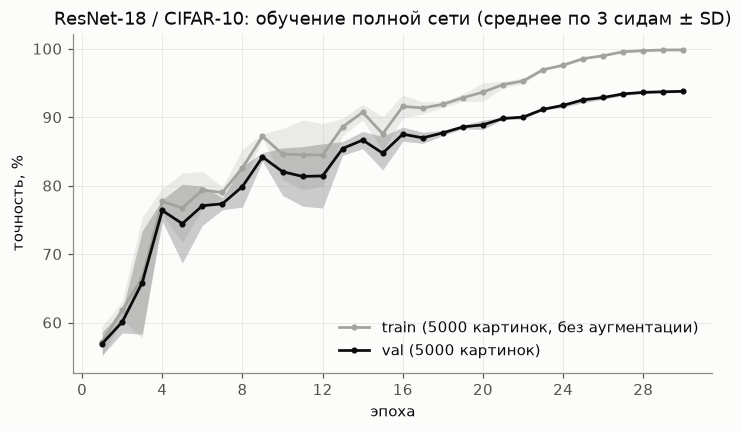

In [13]:
epochs = [h["epoch"] for h in BASE_ROWS[SEEDS[0]]["history"]]
curves = {"train (5000 картинок, без аугментации)": ("train_acc", "#a3a29c"), "val (5000 картинок)": ("val_acc", "#0b0b0b")}
fig, ax = plt.subplots(figsize=(7.5, 4))
for label, (key, color) in curves.items():
    acc = np.array([[100 * h[key] for h in BASE_ROWS[s]["history"]] for s in SEEDS])
    m, s = acc.mean(0), sd(acc)
    ax.plot(epochs, m, color=color, marker="o", ms=3, label=label)
    ax.fill_between(epochs, m - s, m + s, color=color, alpha=0.2, lw=0)
ax.set_xlabel("эпоха")
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_ylabel("точность, %")
ax.set_title(f"{NET_NAME}: обучение полной сети (среднее по {len(SEEDS)} сидам ± SD)")
ax.legend(loc="lower right")
plt.show()

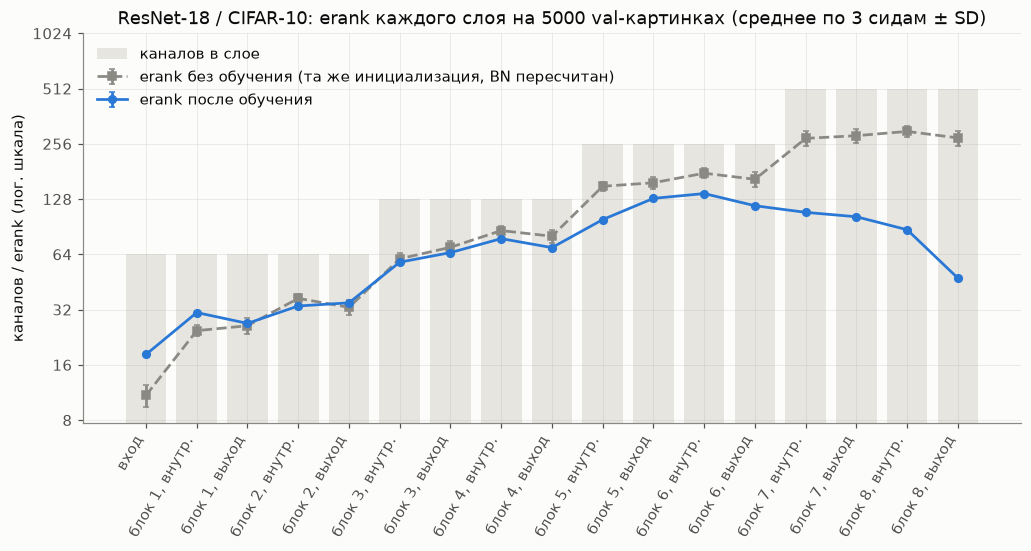

In [14]:
layers0 = BASE_ROWS[SEEDS[0]]["layers"]
names, widths_all = layer_labels(layers0), [m["width"] for m in layers0]
trained = np.array([[m["erank_energy"] for m in BASE_ROWS[s]["layers"]] for s in SEEDS])
untrained = np.array([[m["erank_energy"] for m in BASE_ROWS[s]["untrained_layers"]] for s in SEEDS])
x = np.arange(len(names))
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.bar(x, widths_all, color="#e6e5e0", label="каналов в слое")
ax.errorbar(x, untrained.mean(0), yerr=sd(untrained), fmt="s--", color="#8a8984", capsize=2, ms=5,
            label="erank без обучения (та же инициализация, BN пересчитан)")
ax.errorbar(x, trained.mean(0), yerr=sd(trained), fmt="o-", color=PALETTE["erank"], capsize=2, ms=5,
            label="erank после обучения")
log2_axis(ax, [widths_all, trained.mean(0), untrained.mean(0)])
ax.set_xticks(x, names, rotation=60, ha="right")
ax.set_ylabel("каналов / erank (лог. шкала)")
ax.set_title(f"{NET_NAME}: erank каждого слоя на 5000 val-картинках (среднее по {len(SEEDS)} сидам ± SD)")
ax.legend(loc="upper left")
plt.show()

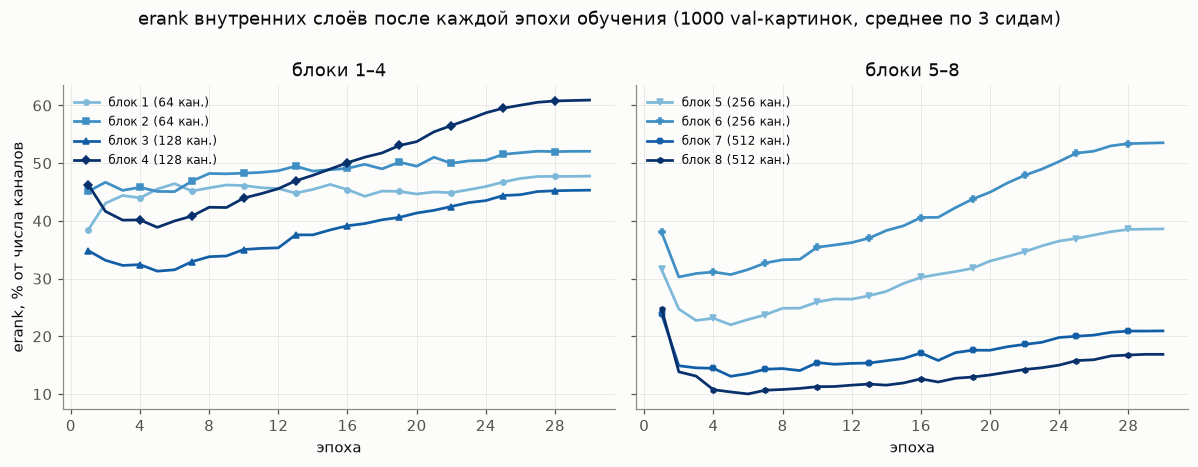

**Вывод.** Полная сеть: test 92,81 ± 0,20% (n=3). erank внутренних слоёв после обучения — от 17% до 61% числа каналов; ниже, чем у необученной сети той же инициализации, — в блоках 2, 3, 4, 5, 6, 7, 8 из 8. С 1-й по 30-ю эпоху (1000 val-картинок) erank блока 1 изменился 24,6 → 30,6, блока 8 — 127,0 → 86,4.

In [15]:
inner_idx = [i for i, m in enumerate(layers0) if m["layer"].endswith("inner")]
n_blocks = len(inner_idx)
block_colors = plt.cm.Blues(np.linspace(0.35, 1.0, n_blocks))
per_epoch = np.array([[h["erank"] for h in BASE_ROWS[s]["history"]] for s in SEEDS])  # seed, epoch, layer
half = (n_blocks + 1) // 2
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, part in zip(axes, [range(half), range(half, n_blocks)]):
    colors = plt.cm.Blues(np.linspace(0.45, 1.0, len(part)))
    for color, b in zip(colors, part):
        i = inner_idx[b]
        share = 100 * per_epoch[:, :, i] / widths_all[i]
        ax.plot(epochs, share.mean(0), color=color, marker=BLOCK_MARKERS[b], ms=3.5, markevery=max(1, len(epochs) // 10),
                label=f"блок {b + 1} ({widths_all[i]} кан.)")
    ax.set_xlabel("эпоха")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_title(f"блоки {part[0] + 1}–{part[-1] + 1}")
    ax.legend(fontsize=8, loc="best")
axes[0].set_ylabel("erank, % от числа каналов")
fig.suptitle(f"erank внутренних слоёв после каждой эпохи обучения (1000 val-картинок, среднее по {len(SEEDS)} сидам)",
             y=1.0)
plt.tight_layout()
plt.show()

acc = [100 * BASE_ROWS[s]["test_acc"] for s in SEEDS]
share_end = 100 * trained.mean(0)[inner_idx] / np.array(widths_all)[inner_idx]
lower = [str(b) for b, i in enumerate(inner_idx, 1) if trained.mean(0)[i] < untrained.mean(0)[i]]
first, last = per_epoch[:, 0, inner_idx].mean(0), per_epoch[:, -1, inner_idx].mean(0)
over = (f"С 1-й по {len(epochs)}-ю эпоху (1000 val-картинок) erank блока 1 изменился {num(first[0], 1)} → "
        f"{num(last[0], 1)}, блока {n_blocks} — {num(first[-1], 1)} → {num(last[-1], 1)}." if len(epochs) > 1 else
        f"После единственной эпохи erank блока 1 — {num(first[0], 1)}, блока {n_blocks} — {num(first[-1], 1)}.")
display(Markdown(
    f"**Вывод.** Полная сеть: test {num(np.mean(acc))} ± {num(sd(acc))}% (n={len(SEEDS)}). erank внутренних слоёв "
    f"после обучения — от {num(share_end.min(), 0)}% до {num(share_end.max(), 0)}% числа каналов; ниже, чем у "
    f"необученной сети той же инициализации, — "
    + (f"в блок{'е' if len(lower) == 1 else 'ах'} {', '.join(lower)} из {n_blocks}" if lower
       else f"ни в одном из {n_blocks} блоков")
    + f". {over}"))

## Шаг 2. Какая мера лучше предсказывает, насколько можно сжать слой

Для каждого блока: шесть мер спектра внутреннего слоя (5000 val-картинок), erank в трёх других точках (выход conv1
до BN, после BN до ReLU, только дисперсии каналов) и вариант статьи arXiv 2607.19315 — erank ковариации позиций
**одной** картинки, среднее по 500 картинкам (новый код, предел H·W − 1 на картинку). «Сколько каналов нужно блоку»
измеряется напрямую: один блок сжимается до k (L1-срез каналов либо PCA-проекция входа conv2 на k направлений),
BN пересчитывается на train, потребность — наименьшее k с потерей val не больше 1 п.п. Мера хороша, если упорядочивает
блоки так же, как потребность (Spearman по блокам, среднее по сидам).

In [16]:
POINTS = {}
for seed in SEEDS:
    base = BASES[seed]

    def measure_points():
        out = {}
        for where, modules in {"conv": [b.conv1 for b in base.blocks], "bn": [b.bn1 for b in base.blocks]}.items():
            covs = channel_covariances(base, data["x_val"], modules=modules)
            out[where] = [all_metrics(eigvals_desc(c)) for c in covs]
        covs = channel_covariances(base, data["x_val"])[1::2]  # control: only the channel variances
        out["diag"] = [all_metrics(c.diagonal().clamp(min=0).sort(descending=True).values.cpu()) for c in covs]
        out["per_image"] = per_image_erank(base, data["x_val"][:PER_IMAGE_N])
        out["per_image_limit"] = [p - 1 for p in inner_positions(base)]
        return out

    POINTS[seed] = cached(f"point|{TAG}|s{seed}|e{EPOCHS}", measure_points)
free()
print("erank одной картинки, сид", SEEDS[0], [round(e, 1) for e in POINTS[SEEDS[0]]["per_image"]])

erank одной картинки, сид 0 [21.9, 29.3, 39.2, 47.8, 30.1, 30.9, 10.1, 7.7]


In [17]:
SENS_ROWS.clear()
x_bn, x_pca = data["x_train"][:BN_N], data["x_train"][PCA_ROWS[0]:PCA_ROWS[1]]  # training pictures, not val
val = (data["x_val"], data["y_val"])
for seed in SEEDS:
    base = BASES[seed]
    widths = base.inner_widths()

    def reference():  # the full network gets the same BatchNorm recalibration as every cut network
        model = copy.deepcopy(base)
        recalibrate_bn(model, x_bn)
        return {"val_acc": evaluate(model, *val)["acc"]}

    ref = cached(f"sens|{TAG}|full|s{seed}|e{EPOCHS}", reference)
    SENS_ROWS.append({"kind": "full", "seed": seed, "val_acc": ref["val_acc"]})
    l1, stats = channel_scores(base, "l1"), {}
    for b, width in enumerate(widths):
        ks = sorted({max(1, round(f * width)) for f in SENS_FRACTIONS})

        def cut_block():
            if not stats:  # PCA statistics, once per base
                stats["covs"], stats["means"] = channel_covariances(base, x_pca), inner_means(base, x_pca)
            out = {"block": b + 1, "width": width, "k": ks, "prune": [], "pca": []}
            for k in ks:
                for kind in ["prune", "pca"]:
                    if kind == "prune":
                        keep = [torch.arange(w) for w in widths]
                        keep[b] = top_k(l1[b], k)
                        model = keep_inner(base, keep)
                    else:
                        ranks = list(widths)
                        ranks[b] = k
                        model = lowrank_conv2(base, ranks, basis="pca", blocks=[b], covs=stats["covs"],
                                              means=stats["means"])
                    recalibrate_bn(model, x_bn)
                    out[kind].append(evaluate(model, *val)["acc"])
            log(f"  чувствительность s{seed}, блок {b + 1}", show=False)
            return out

        row = cached(f"sens|{TAG}|b{b + 1}|s{seed}|e{EPOCHS}|k={ks}", cut_block)
        for kind in ["prune", "pca"]:
            SENS_ROWS.extend({"kind": kind, "block": b + 1, "width": width, "k": k, "seed": seed, "val_acc": a}
                             for k, a in zip(row["k"], row[kind]))
    log(f"Шаг 2: чувствительность сида {seed} готова")
free()

Шаг 2: чувствительность сида 0 готова


Шаг 2: чувствительность сида 1 готова


Шаг 2: чувствительность сида 2 готова


,ширина,erank λ,erank σ,PR,stable,90% энергии,99% энергии,erank conv,erank bn,erank diag,erank 1 картинки,предел H·W−1,нужно L1,нужно PCA
блок,,,,,,,,,,,,,,
1,64,30.8,53.1,18.1,6.0,32.7,58.3,17.4,18.1,58.2,21.8,1023,29.3,8.0
2,64,33.5,54.4,21.0,7.9,36.0,59.0,14.7,17.2,56.2,28.8,1023,29.3,14.7
3,128,58.0,105.0,35.0,12.6,66.0,116.7,25.7,26.7,124.8,39.1,255,64.0,14.7
4,128,77.9,114.1,51.2,18.5,83.7,122.0,38.3,38.9,124.5,48.7,255,64.0,29.3
5,256,99.0,206.4,51.2,15.1,128.3,234.7,43.5,44.3,251.6,30.3,63,106.7,26.7
6,256,137.2,222.8,81.9,25.3,160.0,243.0,60.9,61.2,251.4,31.1,63,128.0,48.0
7,512,108.4,362.9,48.5,13.7,171.0,443.3,50.9,53.3,502.7,10.1,15,117.3,26.7
8,512,87.1,335.0,40.3,13.7,123.3,414.0,40.7,43.1,495.5,7.7,15,69.3,16.0


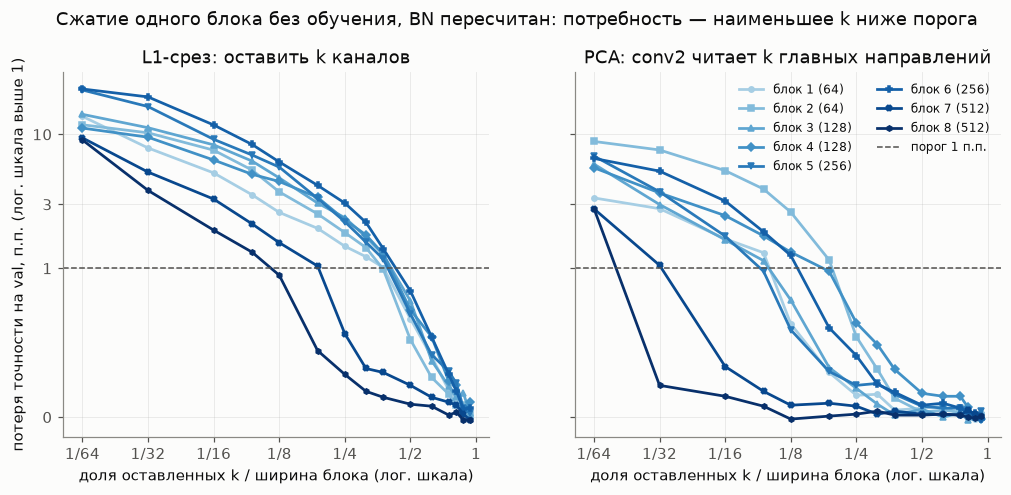

In [18]:
NEED = {kind: needed_widths(SENS_ROWS, kind, SENS_DROP) for kind in ["prune", "pca"]}
MEAS = {}
for s in SEEDS:
    MEAS[s] = block_measures(BASE_ROWS[s]["layers"])
    for where in ["conv", "bn", "diag"]:
        MEAS[s][where] = [m["erank_energy"] for m in POINTS[s][where]]
    MEAS[s]["per_image"] = POINTS[s]["per_image"]
blocks = range(1, n_blocks + 1)


def seed_mean(key):
    return np.mean([MEAS[s][key] for s in SEEDS], axis=0)


table = pd.DataFrame({
    "ширина": MEAS[SEEDS[0]]["width"], "erank λ": seed_mean("erank_energy"), "erank σ": seed_mean("erank_sv"),
    "PR": seed_mean("participation_ratio"), "stable": seed_mean("stable_rank"), "90% энергии": seed_mean("energy90"),
    "99% энергии": seed_mean("energy99"), "erank conv": seed_mean("conv"), "erank bn": seed_mean("bn"),
    "erank diag": seed_mean("diag"), "erank 1 картинки": seed_mean("per_image"),
    "предел H·W−1": POINTS[SEEDS[0]]["per_image_limit"],
    "нужно L1": [np.mean([NEED["prune"][(s, b)] for s in SEEDS]) for b in blocks],
    "нужно PCA": [np.mean([NEED["pca"][(s, b)] for s in SEEDS]) for b in blocks],
}, index=pd.Index(list(blocks), name="блок"))
display(table.round(1))

ref = {r["seed"]: 100 * r["val_acc"] for r in by(SENS_ROWS, kind="full")}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, kind, title in [(axes[0], "prune", "L1-срез: оставить k каналов"),
                        (axes[1], "pca", "PCA: conv2 читает k главных направлений")]:
    for b, color in zip(blocks, block_colors):
        rows = by(SENS_ROWS, kind=kind, block=b)
        ks = sorted({r["k"] for r in rows})
        drop = [np.mean([ref[r["seed"]] - 100 * r["val_acc"] for r in rows if r["k"] == k]) for k in ks]
        ax.plot([k / rows[0]["width"] for k in ks], drop, color=color, marker=BLOCK_MARKERS[b - 1], ms=3.5,
                label=f"блок {b} ({rows[0]['width']})")
    ax.axhline(SENS_DROP, color="#52514e", ls="--", lw=1, label="порог 1 п.п.")
    ax.set_xscale("log", base=2)
    fractions = [f for f in [1 / 64, 1 / 32, 1 / 16, 1 / 8, 1 / 4, 1 / 2, 1] if min(SENS_FRACTIONS) / 2 <= f <= 1]
    ax.set_xticks(fractions, ["1" if f == 1 else f"1/{round(1 / f)}" for f in fractions])
    ax.minorticks_off()
    ax.set_yscale("symlog", linthresh=1)
    ax.set_xlabel("доля оставленных k / ширина блока (лог. шкала)")
    ax.set_title(title)
lo, hi = axes[0].get_ylim()
yticks = [t for t in [-10, -3, -1, 0, 1, 3, 10, 30, 100] if lo <= t <= hi]
axes[0].set_yticks(yticks, [str(t) for t in yticks])
axes[0].set_ylabel("потеря точности на val, п.п. (лог. шкала выше 1)")
axes[1].legend(fontsize=8, ncol=2, loc="upper right")
fig.suptitle("Сжатие одного блока без обучения, BN пересчитан: потребность — наименьшее k ниже порога", y=1.01)
plt.show()

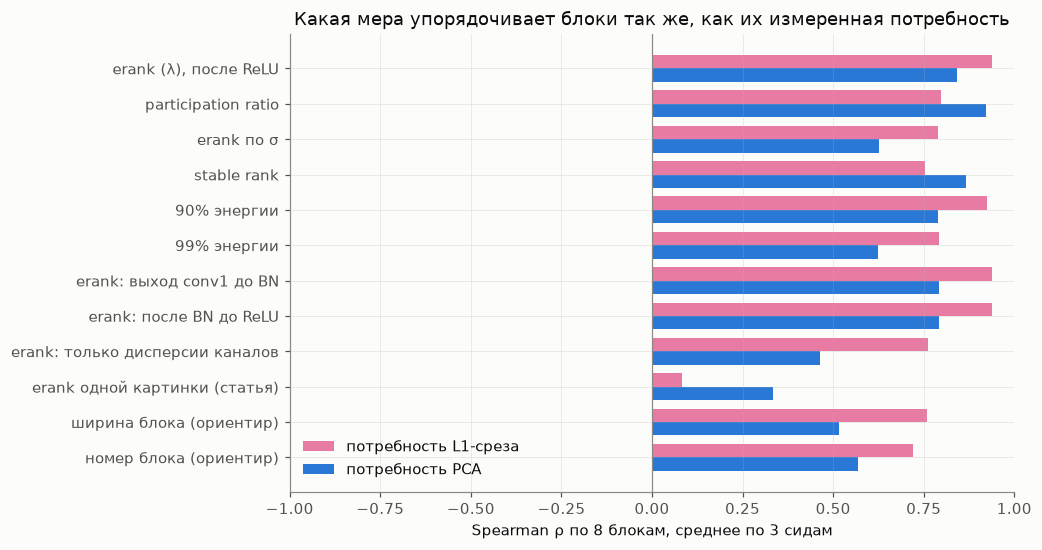

,ρ с потребностью L1,ρ с потребностью PCA
"erank (λ), после ReLU",0.937,0.841
participation ratio,0.799,0.923
erank по σ,0.790,0.625
stable rank,0.754,0.866
90% энергии,0.925,0.788
99% энергии,0.792,0.623
erank: выход conv1 до BN,0.937,0.792
erank: после BN до ReLU,0.937,0.792
erank: только дисперсии каналов,0.762,0.463
erank одной картинки (статья),0.082,0.334


In [19]:
RHO = {kind: sensitivity_rhos(NEED[kind], MEAS) for kind in NEED}
order = ["erank_energy", "participation_ratio", "erank_sv", "stable_rank", "energy90", "energy99",
         "conv", "bn", "diag", "per_image", "width", "depth"]
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8.5, 5.4))
for j, (kind, label) in enumerate([("prune", "потребность L1-среза"), ("pca", "потребность PCA")]):
    ax.barh(y + (j - 0.5) * 0.38, [RHO[kind][m] for m in order], height=0.38,
            color=PALETTE["l1" if kind == "prune" else "pca"], label=label)
ax.set_yticks(y, [MEASURE_LABELS[m] for m in order])
ax.invert_yaxis()
ax.axvline(0, color="#8a8984", lw=0.8)
ax.set_xlim(-1, 1)
ax.set_xlabel(f"Spearman ρ по {n_blocks} блокам, среднее по {len(SEEDS)} сидам")
ax.set_title("Какая мера упорядочивает блоки так же, как их измеренная потребность")
ax.legend(loc="lower left")
plt.show()
display(pd.DataFrame({"ρ с потребностью L1": {MEASURE_LABELS[m]: RHO["prune"][m] for m in order},
                      "ρ с потребностью PCA": {MEASURE_LABELS[m]: RHO["pca"][m] for m in order}}).round(3))

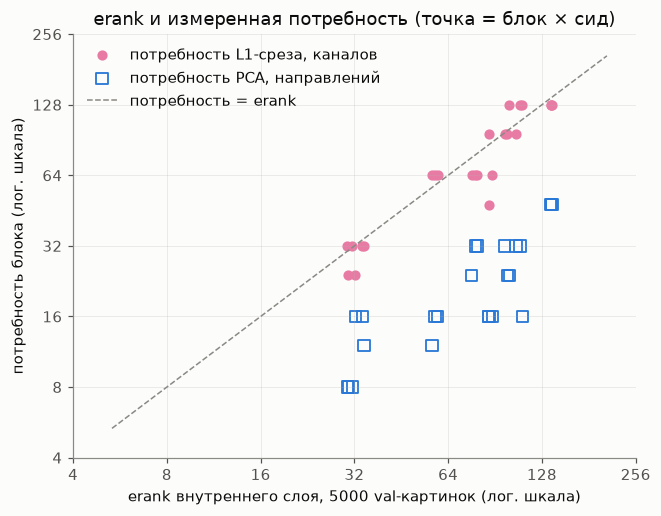

**Вывод.** Потребность L1-среза: erank ρ = 0,94 (место 1 из 10), лучшая мера — erank (λ), после ReLU (ρ = 0,94); ориентиры: ширина ρ = 0,76, номер блока ρ = 0,72. Потребность PCA: erank ρ = 0,84, лучшая — participation ratio (ρ = 0,92). Точка замера (L1): conv 0,94, bn 0,94, после ReLU 0,94, только дисперсии 0,76. erank одной картинки: ρ = 0,08 (L1) и 0,33 (PCA). В среднем L1-срезу нужно 0,95×erank каналов, PCA — 0,30×erank направлений. По блокам потребность L1 / erank — от 0,80 до 1,10: ближе всего к erank в блоке 1 (0,95×), дальше всего — в блоке 8 (0,80×).

In [20]:
fig, ax = plt.subplots(figsize=(6.6, 5))
for kind, label, marker, size in [("prune", "потребность L1-среза, каналов", "o", 30),
                                  ("pca", "потребность PCA, направлений", "s", 55)]:
    xs = [MEAS[s]["erank_energy"][b - 1] for s in SEEDS for b in blocks]
    ys = [NEED[kind][(s, b)] for s in SEEDS for b in blocks]
    color = PALETTE["l1" if kind == "prune" else "pca"]
    ax.scatter(xs, ys, marker=marker, s=size, label=label, linewidths=1.2,
               **({"color": color} if kind == "prune" else {"facecolors": "none", "edgecolors": color}))
values = [MEAS[s]["erank_energy"][b - 1] for s in SEEDS for b in blocks] + \
         [NEED[k][(s, b)] for k in NEED for s in SEEDS for b in blocks]
lim = [max(1, min(values) / 1.5), max(values) * 1.5]
ax.plot(lim, lim, color="#8a8984", ls="--", lw=1, label="потребность = erank")
log2_axis(ax, values, "x")
log2_axis(ax, values, "y")
ax.set_xlabel("erank внутреннего слоя, 5000 val-картинок (лог. шкала)")
ax.set_ylabel("потребность блока (лог. шкала)")
ax.set_title("erank и измеренная потребность (точка = блок × сид)")
ax.legend(loc="upper left")
plt.show()

ratio = {k: np.mean([NEED[k][(s, b)] / MEAS[s]["erank_energy"][b - 1] for s in SEEDS for b in blocks]) for k in NEED}
measures_only = [m for m in order if m not in ("width", "depth")]


def place(kind, m):
    finite = sorted((v for k, v in RHO[kind].items() if k in measures_only and not np.isnan(v)), reverse=True)
    return finite.index(RHO[kind][m]) + 1 if not np.isnan(RHO[kind][m]) else "—"


def best(kind):
    finite = {k: v for k, v in RHO[kind].items() if k in measures_only and not np.isnan(v)}
    return max(finite, key=finite.get) if finite else "erank_energy"


# per block: need / erank (mean over seeds); where erank names the needed number of channels best and worst
block_ratio = {k: [np.mean([NEED[k][(s, b)] / MEAS[s]["erank_energy"][b - 1] for s in SEEDS]) for b in blocks]
               for k in NEED}
dist = [abs(np.log(x)) for x in block_ratio["prune"]]
close_b, far_b = int(np.argmin(dist)) + 1, int(np.argmax(dist)) + 1
display(Markdown(
    f"**Вывод.** Потребность L1-среза: erank ρ = {num(RHO['prune']['erank_energy'])} "
    f"(место {place('prune', 'erank_energy')} из {len(measures_only)}), лучшая мера — "
    f"{MEASURE_LABELS[best('prune')]} (ρ = {num(RHO['prune'][best('prune')])}); ориентиры: ширина "
    f"ρ = {num(RHO['prune']['width'])}, номер блока ρ = {num(RHO['prune']['depth'])}. Потребность PCA: erank "
    f"ρ = {num(RHO['pca']['erank_energy'])}, лучшая — {MEASURE_LABELS[best('pca')]} "
    f"(ρ = {num(RHO['pca'][best('pca')])}). Точка замера (L1): conv {num(RHO['prune']['conv'])}, bn "
    f"{num(RHO['prune']['bn'])}, после ReLU {num(RHO['prune']['erank_energy'])}, только дисперсии "
    f"{num(RHO['prune']['diag'])}. erank одной картинки: ρ = {num(RHO['prune']['per_image'])} (L1) и "
    f"{num(RHO['pca']['per_image'])} (PCA). В среднем L1-срезу нужно {num(ratio['prune'])}×erank каналов, "
    f"PCA — {num(ratio['pca'])}×erank направлений. По блокам потребность L1 / erank — от "
    f"{num(min(block_ratio['prune']))} до {num(max(block_ratio['prune']))}: ближе всего к erank в блоке {close_b} "
    f"({num(block_ratio['prune'][close_b - 1])}×), дальше всего — в блоке {far_b} "
    f"({num(block_ratio['prune'][far_b - 1])}×)."))

## Шаг 3. Ширины по erank против базовых линий: обучение с нуля

Каждый метод предлагает внутренние ширины блоков под один потолок — долю параметров или MACs полной сети
(MACs — умножения-сложения на одну картинку, FLOPs ≈ 2·MACs), не меньше 8 каналов на блок; сеть с этими ширинами
обучается с нуля тем же рецептом, что и база (3 сида), сравнение с uniform парное по сиду и бюджету.

| метод | как выбираются ширины |
|---|---|
| uniform | одна общая доля от исходных ширин |
| random (случайно) | доли исходных ширин случайно в [0,2; 1] |
| erank, erank по σ | ширины ∝ erank блока (по λ или по σ = √λ) |
| Taylor, \|γ\| BN | глобальный рейтинг всех каналов по Taylor-важности (Molchanov et al., 2019) или по \|γ\| BatchNorm |
| Network Slimming | \|γ\| базы того же сида, обученной со штрафом λ·Σ\|γ\| (Liu et al., 2017) |
| L1-потребность | ширины ∝ потребности L1-среза из шага 2 (анализ чувствительности Li et al., 2017) |
| erank / цена, только цена | доля бюджета блока ∝ erank (или одинакова), с учётом цены канала в параметрах |

Вторая часть — low-rank без изменения ширин: conv2 каждого блока заменяется парой свёрток ранга 0,5 / 1 / 2 × erank —
по главным направлениям активаций (PCA, с картой из единиц для точного среднего у границ) или по SVD весов; точность
до и после 5 эпох дообучения.

In [21]:
SLIM_ROWS = {}


def make_slim(seed: int):
    log(f"Шаг 3: база со штрафом Slimming λ={SLIM_L1:g}, сид {seed}")
    torch.manual_seed(seed)
    model = new_model().to(DEVICE)
    history = train(model, data, EPOCHS, LR, seed=seed, verbose=False, l1_gamma=SLIM_L1)
    gammas = channel_scores(model, "gamma")
    return model, {"seed": seed, "l1_gamma": SLIM_L1, "val_acc": history[-1]["val_acc"],
                   "test_acc": evaluate(model, data["x_test"], data["y_test"])["acc"],
                   "share_gamma_below_0.01": [round(float((g < 1e-2).float().mean()), 3) for g in gammas],
                   **describe(model)}


for seed in SEEDS:
    SLIM[seed], SLIM_ROWS[seed] = cached_net(f"slim|{TAG}|l1={SLIM_L1}|s{seed}|e{EPOCHS}", lambda: make_slim(seed))
free()
display(pd.DataFrame([{"сид": s, "val без штрафа, %": 100 * BASE_ROWS[s]["history"][-1]["val_acc"],
                       "val со штрафом, %": 100 * SLIM_ROWS[s]["val_acc"],
                       "доля |γ| < 0,01 по блокам": SLIM_ROWS[s]["share_gamma_below_0.01"]} for s in SEEDS]).round(2))

,сид,"val без штрафа, %","val со штрафом, %","доля |γ| < 0,01 по блокам"
0,0,93.70,93.34,"[0.219, 0.266, 0.281, 0.312, 0.492, 0.539, 0.8..."
1,1,93.94,93.72,"[0.25, 0.266, 0.344, 0.328, 0.504, 0.539, 0.82..."
2,2,93.68,93.86,"[0.203, 0.25, 0.273, 0.328, 0.516, 0.555, 0.82..."


In [22]:
ALLOC = []
plan = [(seed, measure, budget, method) for seed in SEEDS
        for measure, budgets, methods in [("params", PARAM_BUDGETS, PARAM_METHODS), ("macs", MAC_BUDGETS, MAC_METHODS)]
        for budget in budgets for method in methods]
log(f"Шаг 3: сетей в плане — {len(plan)} (одинаковые ширины обучаются один раз)")
t0 = time.time()
for i, (seed, measure, budget, method) in enumerate(plan, 1):
    row = scratch(chosen_widths(method, seed, measure, budget), seed)
    ALLOC.append({"method": method, "measure": measure, "budget": budget, "seed": seed,
                  **{k: row[k] for k in ["test_acc", "val_acc", "train_acc", "params", "macs", "inner_widths"]}})
    if i % 10 == 0 or i == len(plan):
        log(f"Шаг 3: {i}/{len(plan)} готово, {(time.time() - t0) / 60:.1f} мин в этом запуске")
free()

Шаг 3: сетей в плане — 102 (одинаковые ширины обучаются один раз)


Шаг 3: 10/102 готово, 0.0 мин в этом запуске


Шаг 3: 20/102 готово, 0.0 мин в этом запуске


Шаг 3: 30/102 готово, 0.0 мин в этом запуске


Шаг 3: 40/102 готово, 0.0 мин в этом запуске


Шаг 3: 50/102 готово, 0.0 мин в этом запуске


... (2 outputs left out)

Шаг 3: 80/102 готово, 0.0 мин в этом запуске


Шаг 3: 90/102 готово, 0.0 мин в этом запуске


Шаг 3: 100/102 готово, 0.0 мин в этом запуске


Шаг 3: 102/102 готово, 0.0 мин в этом запуске


In [23]:
LOWRANK = []
for seed in SEEDS:
    base, metrics = BASES[seed], BASE_ROWS[seed]["layers"]
    eranks = inner(metrics, "erank_energy")
    for mult in LOWRANK_MULTS:
        ranks = [min(w, max(4, round(mult * e))) for e, w in zip(eranks, base.inner_widths())]
        for basis in ["pca", "svd"]:
            def factorize():
                model = lowrank_conv2(base, ranks, data["x_val"], basis=basis)
                raw = evaluate(model, data["x_val"], data["y_val"])["acc"]
                recalibrate_bn(model, data["x_train"][:BN_N])
                before = evaluate(model, data["x_val"], data["y_val"])["acc"]
                test_before = evaluate(model, data["x_test"], data["y_test"])["acc"]
                train(model, data, LOWRANK_FT_EPOCHS, FT_LR, seed=seed, verbose=False, **TRAIN_KW)
                test = evaluate(model, data["x_test"], data["y_test"])["acc"]
                log(f"  low-rank {basis} ×{mult} s{seed}: {test_before:.4f} -> {test:.4f}", show=False)
                return {"basis": basis, "mult": mult, "ranks": ranks, "seed": seed,
                        **({"pca_mean": "exact"} if basis == "pca" else {}),
                        "val_acc_raw": raw, "val_acc_before_ft": before, "test_acc_before_ft": test_before,
                        "test_acc": test, "params": count_params(model), "macs": count_macs(model)}

            LOWRANK.append(cached(f"lowrank|{TAG}|{basis}|{mult}|s{seed}|e{EPOCHS}|ft{LOWRANK_FT_EPOCHS}", factorize))
log("Шаг 3: low-rank готов")
free()

Шаг 3: low-rank готов


In [24]:
FULL = {"params": BASE_ROWS[SEEDS[0]]["params"], "macs": BASE_ROWS[SEEDS[0]]["macs"]}
FULL_ACC = [100 * BASE_ROWS[s]["test_acc"] for s in SEEDS]
SUMMARY = {}  # (measure, budget, method) -> paired summary of method - uniform, p.p.
out = []
for measure, budgets, methods in [("params", PARAM_BUDGETS, PARAM_METHODS), ("macs", MAC_BUDGETS, MAC_METHODS)]:
    rows = by(ALLOC, measure=measure)
    for budget in budgets:
        for method in methods:
            sel = by(rows, method=method, budget=budget)
            acc_m, acc_s = mean_std([100 * r["test_acc"] for r in sel])
            if method != "uniform":
                SUMMARY[(measure, budget, method)] = paired_summary(paired_diffs(rows, method, budget))
            out.append({"потолок": budget_label(measure, budget), "метод": LABELS[method],
                        "test, %": round(acc_m, 2), "SD": round(acc_s, 2),
                        "Δ к uniform, п.п. [t95] (n)": ci_text(SUMMARY[(measure, budget, method)])
                        if method != "uniform" else "база сравнения",
                        "params/full, %": round(100 * np.mean([r["params"] for r in sel]) / FULL["params"], 1),
                        "MACs/full, %": round(100 * np.mean([r["macs"] for r in sel]) / FULL["macs"], 1)})
pd.set_option("display.max_rows", 200)
display(pd.DataFrame(out))

,потолок,метод,"test, %",SD,"Δ к uniform, п.п. [t95] (n)","params/full, %","MACs/full, %"
0,25% параметров,uniform (равномерно),91.93,0.12,база сравнения,24.8,24.6
1,25% параметров,random (случайно),91.50,0.38,"−0,43 [−1,13; +0,26] (n=3)",24.9,25.0
2,25% параметров,erank,92.52,0.08,"+0,59 [+0,48; +0,70] (n=3)",24.8,39.4
3,25% параметров,Taylor (глобально),92.97,0.12,"+1,04 [+0,51; +1,57] (n=3)",25.0,72.8
4,25% параметров,|γ| BN (глобально),92.13,0.21,"+0,20 [−0,49; +0,89] (n=3)",25.0,30.3
5,25% параметров,"Network Slimming (λ=0,001)",92.76,0.24,"+0,83 [+0,35; +1,32] (n=3)",25.0,52.2
6,25% параметров,L1-потребность,92.43,0.31,"+0,50 [−0,48; +1,47] (n=3)",24.9,39.2
7,25% параметров,erank / цена канала,92.79,0.13,"+0,86 [+0,26; +1,46] (n=3)",24.9,67.1
8,25% параметров,только цена канала,92.80,0.13,"+0,87 [+0,51; +1,23] (n=3)",25.0,66.4
9,10% параметров,uniform (равномерно),90.46,0.22,база сравнения,9.9,10.8


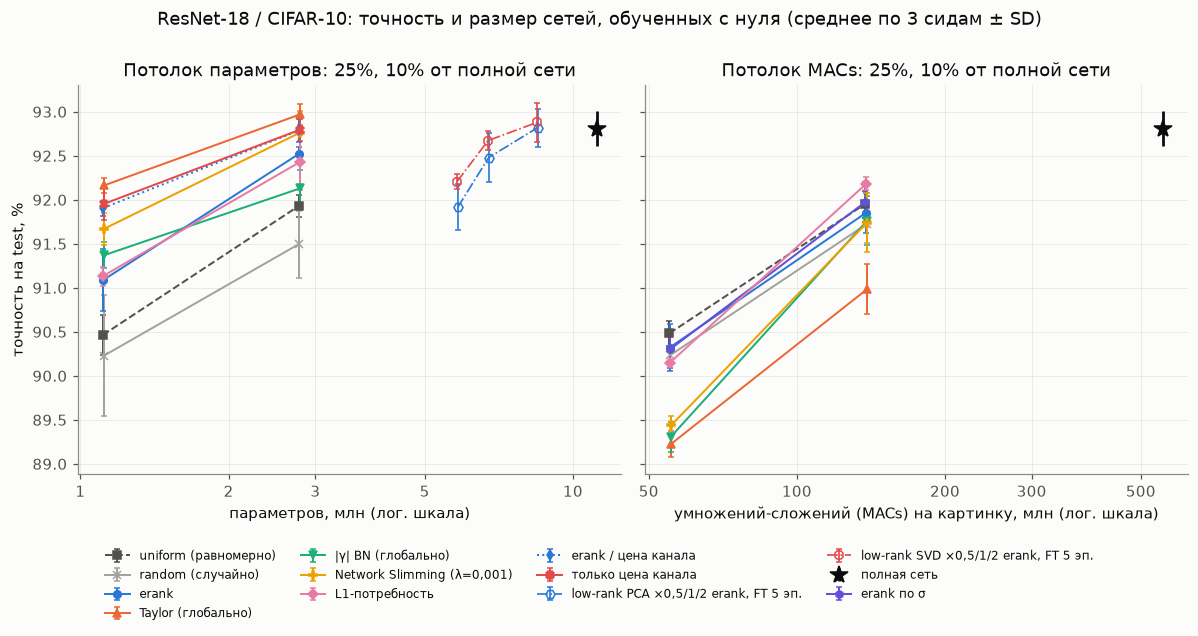

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, measure, budgets, methods in [(axes[0], "params", PARAM_BUDGETS, PARAM_METHODS),
                                      (axes[1], "macs", MAC_BUDGETS, MAC_METHODS)]:
    rows = by(ALLOC, measure=measure)
    for method in methods:
        pts = []
        for budget in sorted(budgets):
            sel = by(rows, method=method, budget=budget)
            pts.append((np.mean([r[measure] for r in sel]) / 1e6, *mean_std([100 * r["test_acc"] for r in sel])))
        xs, ys, es = zip(*pts)
        st = style(method)
        ax.errorbar(xs, ys, yerr=es, color=st["color"], marker=st["marker"], ls=st["ls"], label=st["label"],
                    capsize=2, lw=1.3, ms=5)
    if measure == "params":
        for basis in ["pca", "svd"]:
            pts = []
            for mult in LOWRANK_MULTS:
                sel = by(LOWRANK, basis=basis, mult=mult)
                pts.append((np.mean([r["params"] for r in sel]) / 1e6, *mean_std([100 * r["test_acc"] for r in sel])))
            xs, ys, es = zip(*pts)
            ax.errorbar(xs, ys, yerr=es, color=PALETTE[basis], marker=MARKERS[basis], mfc="none", ls="-.",
                        capsize=2, lw=1.1, ms=6, label=f"{LABELS[basis]} ×0,5/1/2 erank, FT {LOWRANK_FT_EPOCHS} эп.")
    ax.errorbar(FULL[measure] / 1e6, np.mean(FULL_ACC), yerr=sd(FULL_ACC), color="#0b0b0b", marker="*", ms=12,
                ls="none", label="полная сеть")
    plain_log_axis(ax, LOG_TICKS)
    ax.set_xlabel(("параметров" if measure == "params" else "умножений-сложений (MACs) на картинку")
                  + ", млн (лог. шкала)")
    ax.set_title(f"Потолок {RESOURCE[measure]}: {', '.join(f'{b:.0%}' for b in budgets)} от полной сети")
axes[0].set_ylabel("точность на test, %")
handles, labels = {}, []
for ax in axes:
    for h, l in zip(*ax.get_legend_handles_labels()):
        handles.setdefault(l, h)
fig.legend(handles.values(), handles.keys(), loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=4, fontsize=8)
fig.suptitle(f"{NET_NAME}: точность и размер сетей, обученных с нуля (среднее по {len(SEEDS)} сидам ± SD)", y=1.0)
plt.tight_layout()
plt.show()

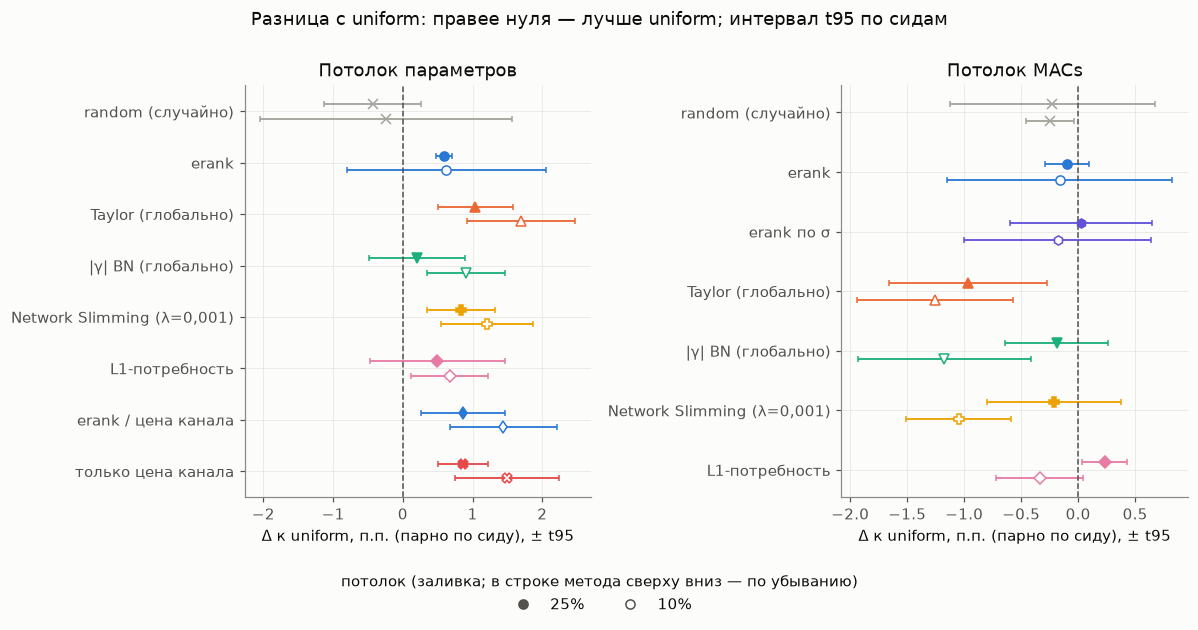

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
ALL_BUDGETS = sorted(set(PARAM_BUDGETS) | set(MAC_BUDGETS), reverse=True)  # the larger budget filled, then hollow
for ax, measure, budgets, methods in [(axes[0], "params", PARAM_BUDGETS, PARAM_METHODS),
                                      (axes[1], "macs", MAC_BUDGETS, MAC_METHODS)]:
    shown = [m for m in methods if m != "uniform"]
    for i, method in enumerate(shown):
        st = style(method)
        for j, budget in enumerate(budgets):
            s = SUMMARY[(measure, budget, method)]
            yy = i + (j - (len(budgets) - 1) / 2) * 0.28
            err = None if s["ci95_pp"] is None else [[s["mean_pp"] - s["ci95_pp"][0]], [s["ci95_pp"][1] - s["mean_pp"]]]
            ax.errorbar(s["mean_pp"], yy, xerr=err, color=st["color"], marker=st["marker"], ms=6, capsize=2,
                        mfc=st["color"] if ALL_BUDGETS.index(budget) == 0 else "white", ls="none", lw=1.2)
    ax.axvline(0, color=PALETTE["uniform"], ls="--", lw=1)
    ax.set_yticks(range(len(shown)), [LABELS[m] for m in shown])
    ax.invert_yaxis()
    ax.set_xlabel("Δ к uniform, п.п. (парно по сиду), ± t95")
    ax.set_title(f"Потолок {RESOURCE[measure]}")
legend = [plt.Line2D([], [], color="#52514e", marker="o", ls="none", label=f"{b:.0%}",
                     mfc="#52514e" if k == 0 else "white") for k, b in enumerate(ALL_BUDGETS)]
fig.legend(handles=legend, title="потолок (заливка; в строке метода сверху вниз — по убыванию)", loc="upper center",
           bbox_to_anchor=(0.5, 0.0), ncol=len(ALL_BUDGETS))
fig.suptitle("Разница с uniform: правее нуля — лучше uniform; интервал t95 по сидам", y=1.0)
plt.tight_layout()
plt.show()

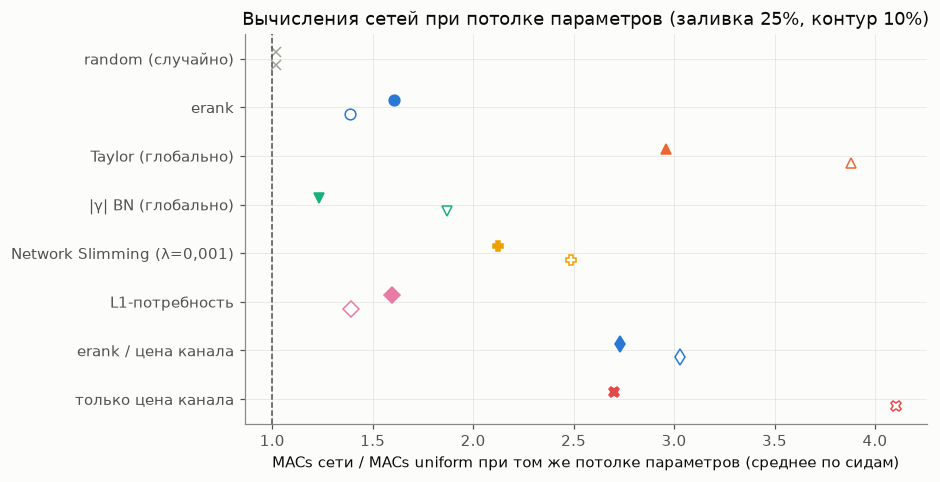

In [27]:
rows = by(ALLOC, measure="params")
shown = [m for m in PARAM_METHODS if m != "uniform"]
fig, ax = plt.subplots(figsize=(8, 4.6))
ratios = {}
for i, method in enumerate(shown):
    st = style(method)
    for j, budget in enumerate(PARAM_BUDGETS):
        uni = {r["seed"]: r["macs"] for r in by(rows, method="uniform", budget=budget)}
        rr = [r["macs"] / uni[r["seed"]] for r in by(rows, method=method, budget=budget)]
        ratios[(method, budget)] = np.mean(rr)
        ax.plot(np.mean(rr), i + (j - (len(PARAM_BUDGETS) - 1) / 2) * 0.28, color=st["color"], marker=st["marker"],
                mfc=st["color"] if j == 0 else "white", ls="none", ms=7)
ax.axvline(1, color=PALETTE["uniform"], ls="--", lw=1)
ax.set_yticks(range(len(shown)), [LABELS[m] for m in shown])
ax.invert_yaxis()
ax.set_xlabel("MACs сети / MACs uniform при том же потолке параметров (среднее по сидам)")
ax.set_title(f"Вычисления сетей при потолке параметров (заливка {PARAM_BUDGETS[0]:.0%}, контур {PARAM_BUDGETS[-1]:.0%})")
plt.show()

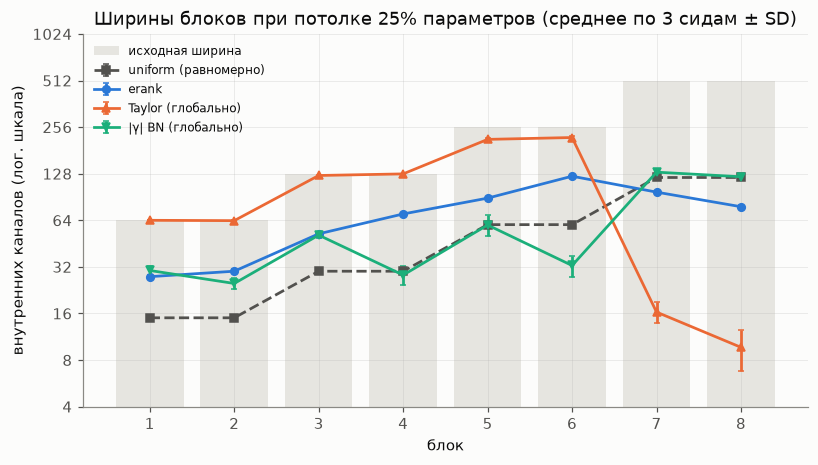

In [28]:
W_BUDGET = 0.25 if 0.25 in PARAM_BUDGETS else PARAM_BUDGETS[0]
rows = by(ALLOC, measure="params", budget=W_BUDGET)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.bar(list(blocks), BASES[SEEDS[0]].inner_widths(), color="#e6e5e0", label="исходная ширина")
for method in ["uniform", "erank", "taylor_global", "gamma_global"]:
    w = np.array([r["inner_widths"] for r in by(rows, method=method)])
    st = style(method)
    ax.errorbar(list(blocks), w.mean(0), yerr=sd(w), color=st["color"], marker=st["marker"], ls=st["ls"],
                label=st["label"], capsize=2, ms=5)
log2_axis(ax, [BASES[SEEDS[0]].inner_widths(), [r["inner_widths"] for r in rows]])
ax.set_xticks(list(blocks))
ax.set_xlabel("блок")
ax.set_ylabel("внутренних каналов (лог. шкала)")
ax.set_title(f"Ширины блоков при потолке {W_BUDGET:.0%} параметров (среднее по {len(SEEDS)} сидам ± SD)")
ax.legend(fontsize=8, loc="upper left")
plt.show()

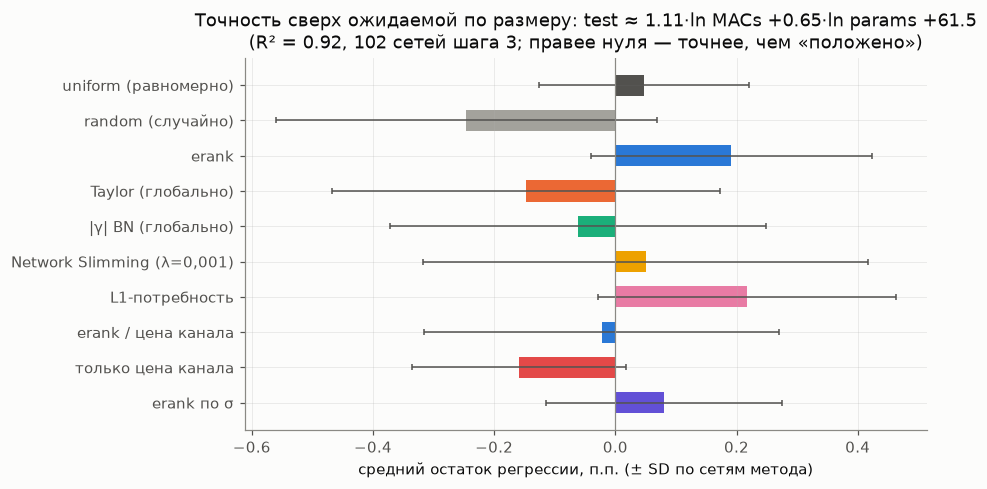

**Вывод.** erank − uniform, п.п. [t95]: 25% параметров: +0,59 [+0,48; +0,70] (n=3); 10% параметров: +0,62 [−0,80; +2,05] (n=3); 25% MACs: −0,10 [−0,29; +0,09] (n=3); 10% MACs: −0,16 [−1,15; +0,83] (n=3). Наибольшая средняя разница с uniform (uniform = 0): 25% параметров — Taylor (глобально) (+1,04); 10% параметров — Taylor (глобально) (+1,70); 25% MACs — L1-потребность (+0,23); 10% MACs — uniform (все методы в среднем ниже). При потолке параметров отношение MACs erank-сети к MACs uniform: 1,60 при 25% и 1,39 при 10%. Остаток регрессии по размеру: erank +0,19 п.п., uniform +0,05 п.п.

In [29]:
A = np.array([[np.log(r["macs"]), np.log(r["params"]), 1.0] for r in ALLOC])
acc_all = np.array([100 * r["test_acc"] for r in ALLOC])
coef, *_ = np.linalg.lstsq(A, acc_all, rcond=None)
resid = acc_all - A @ coef
r2 = 1 - (resid ** 2).sum() / max(((acc_all - acc_all.mean()) ** 2).sum(), 1e-12)
methods_all = list(dict.fromkeys(PARAM_METHODS + MAC_METHODS))
res_by = {m: resid[[r["method"] == m for r in ALLOC]] for m in methods_all}
fig, ax = plt.subplots(figsize=(8, 4.4))
for i, m in enumerate(methods_all):
    ax.barh(i, res_by[m].mean(), xerr=sd(res_by[m]), color=style(m)["color"], height=0.6, capsize=2,
            error_kw={"ecolor": "#52514e", "lw": 1})
ax.axvline(0, color="#8a8984", lw=0.8)
ax.set_yticks(range(len(methods_all)), [LABELS[m] for m in methods_all])
ax.invert_yaxis()
ax.set_xlabel("средний остаток регрессии, п.п. (± SD по сетям метода)")
ax.set_title(f"Точность сверх ожидаемой по размеру: test ≈ {coef[0]:.2f}·ln MACs {coef[1]:+.2f}·ln params "
             f"{coef[2]:+.1f}\n(R² = {r2:.2f}, {len(ALLOC)} сетей шага 3; правее нуля — точнее, чем «положено»)")
plt.show()

def cell(measure, budget, method="erank"):
    return ci_text(SUMMARY[(measure, budget, method)]) if (measure, budget, method) in SUMMARY else "—"

def mean_delta(measure, budget, method):
    """Mean of method - uniform over seeds, p.p. (uniform itself: 0)."""
    return 0.0 if method == "uniform" else SUMMARY[(measure, budget, method)]["mean_pp"]


best_by = {}  # (measure, budget) -> the method with the largest mean difference to uniform, uniform (= 0) included
for measure, budgets in [("params", PARAM_BUDGETS), ("macs", MAC_BUDGETS)]:
    for budget in budgets:
        cand = {"uniform": 0.0, **{m: s["mean_pp"] for (mm, bb, m), s in SUMMARY.items()
                                   if mm == measure and bb == budget}}
        best_by[(measure, budget)] = max(cand, key=cand.get)


def best_text(m, b):
    w = best_by[(m, b)]
    return (f"{budget_label(m, b)} — uniform (все методы в среднем ниже)" if w == "uniform" else
            f"{budget_label(m, b)} — {LABELS[w]} ({num(mean_delta(m, b, w), 2, True)})")


macs_ratio = " и ".join(f"{num(ratios[('erank', b)])} при {b:.0%}" for b in PARAM_BUDGETS)
display(Markdown(
    "**Вывод.** erank − uniform, п.п. [t95]: "
    + "; ".join(f"{budget_label(m, b)}: {cell(m, b)}" for m, bs in [("params", PARAM_BUDGETS), ("macs", MAC_BUDGETS)]
                for b in bs)
    + ". Наибольшая средняя разница с uniform (uniform = 0): " + "; ".join(best_text(m, b) for m, b in best_by)
    + f". При потолке параметров отношение MACs erank-сети к MACs uniform: {macs_ratio}. Остаток регрессии по "
    + f"размеру: erank {num(res_by['erank'].mean(), 2, True)} п.п., uniform {num(res_by['uniform'].mean(), 2, True)} п.п."))

In [30]:
out = []
for basis in ["pca", "svd"]:
    for mult in LOWRANK_MULTS:
        sel = by(LOWRANK, basis=basis, mult=mult)
        gain = paired_summary([100 * (r["test_acc"] - r["test_acc_before_ft"]) for r in sel])
        out.append({"базис": LABELS[basis], "ранг ×erank": mult,
                    "params/full, %": round(100 * np.mean([r["params"] for r in sel]) / FULL["params"], 1),
                    "MACs/full, %": round(100 * np.mean([r["macs"] for r in sel]) / FULL["macs"], 1),
                    "val до пересчёта BN, %": round(100 * np.mean([r["val_acc_raw"] for r in sel]), 2),
                    "val после BN, %": round(100 * np.mean([r["val_acc_before_ft"] for r in sel]), 2),
                    "test до FT (после BN), %": round(100 * np.mean([r["test_acc_before_ft"] for r in sel]), 2),
                    "test после FT, %": round(100 * np.mean([r["test_acc"] for r in sel]), 2),
                    "эффект FT, п.п. [t95]": ci_text(gain)})
display(pd.DataFrame(out))
one = {b: by(LOWRANK, basis=b, mult=1) for b in ["pca", "svd"]}
display(Markdown(
    f"**Вывод.** Low-rank conv2 ранга erank, test до → после {LOWRANK_FT_EPOCHS} эпох FT (BN пересчитан): PCA "
    f"{num(100 * np.mean([r['test_acc_before_ft'] for r in one['pca']]))} → "
    f"{num(100 * np.mean([r['test_acc'] for r in one['pca']]))}%, SVD "
    f"{num(100 * np.mean([r['test_acc_before_ft'] for r in one['svd']]))} → "
    f"{num(100 * np.mean([r['test_acc'] for r in one['svd']]))}% при "
    f"{num(100 * np.mean([r['params'] for r in one['pca']]) / FULL['params'], 0)}% параметров; полная сеть "
    f"{num(np.mean(FULL_ACC))}%. Базис PCA подобран на тех же val-картинках, поэтому val у PCA — не "
    f"независимая проверка (SVD берёт только веса); test независим для обоих."))

,базис,ранг ×erank,"params/full, %","MACs/full, %","val до пересчёта BN, %","val после BN, %","test до FT (после BN), %","test после FT, %","эффект FT, п.п. [t95]"
0,low-rank PCA,0.5,52.2,58.7,89.47,91.09,90.18,91.91,"+1,73 [+1,22; +2,25] (n=3)"
1,low-rank PCA,1.0,60.4,71.5,93.11,93.10,92.26,92.48,"+0,22 [−0,06; +0,50] (n=3)"
2,low-rank PCA,2.0,75.9,94.4,93.75,93.67,92.78,92.82,"+0,04 [−0,11; +0,20] (n=3)"
3,low-rank SVD,0.5,52.0,58.3,88.09,91.66,91.04,92.21,"+1,17 [+0,80; +1,54] (n=3)"
4,low-rank SVD,1.0,60.2,71.1,92.97,93.41,92.37,92.67,"+0,30 [−0,02; +0,62] (n=3)"
5,low-rank SVD,2.0,75.7,94.0,93.73,93.63,92.82,92.88,"+0,06 [−0,19; +0,32] (n=3)"


**Вывод.** Low-rank conv2 ранга erank, test до → после 5 эпох FT (BN пересчитан): PCA 92,26 → 92,48%, SVD 92,37 → 92,67% при 60% параметров; полная сеть 92,81%. Базис PCA подобран на тех же val-картинках, поэтому val у PCA — не независимая проверка (SVD берёт только веса); test независим для обоих.

## Шаг 4. Дообучение среза против обучения с нуля

Ширины uniform и erank вырезаются из обученной базы того же сида: каналы выбираются по L1-норме фильтров conv1
(Li et al., 2017), по среднему рангу карт признаков HRank (Lin et al., 2020, 500 val-картинок) или случайно; ширины
L1-потребности — только с выбором по L1. Затем пересчёт BN, val сразу после среза, 10 эпох дообучения (lr 0,01) и
test. Сравнение — с той же архитектурой, обученной с нуля полным рецептом в шаге 3 (Liu et al., 2019).

In [31]:
FT = []
for seed in SEEDS:
    base, metrics = BASES[seed], BASE_ROWS[seed]["layers"]
    scores = {select: channel_scores(base, select, seed, data) for select in FT_SELECT}
    for budget in PARAM_BUDGETS:
        pairs = [(m, sel) for m in FT_METHODS for sel in FT_SELECT] + [("need", "l1")]
        for method, select in pairs:
            run_id = f"ft|{TAG}|{method}{method_key(method)}|params|{budget}|{select}|s{seed}|e{EPOCHS}|ft{FT_EPOCHS}"
            row = cached(run_id, lambda: finetune_one(base, metrics, scores[select], method, budget, seed, select, data))
            log(f"  FT {method} {budget} {select} s{seed}: {row['val_acc_before_ft']:.4f} -> {row['test_acc']:.4f}",
                show=False)
            FT.append({**row, "scratch_test_acc": scratch(row["inner_widths"], seed)["test_acc"]})
log("Шаг 4 готов")
free()

Шаг 4 готов


,потолок,ширины,выбор каналов,"val сразу после среза, %","test после FT, %","test с нуля, %","FT − с нуля, п.п. [t95]"
0,25% параметров,uniform (равномерно),L1 весов,50.16,91.73,91.93,"−0,20 [−0,47; +0,08] (n=3)"
1,25% параметров,uniform (равномерно),HRank,40.79,91.70,91.93,"−0,23 [−0,61; +0,16] (n=3)"
2,25% параметров,uniform (равномерно),случайно,53.67,91.75,91.93,"−0,18 [−0,80; +0,45] (n=3)"
3,25% параметров,erank,L1 весов,76.53,92.36,92.52,"−0,16 [−0,58; +0,26] (n=3)"
4,25% параметров,erank,HRank,64.76,92.16,92.52,"−0,36 [−0,73; +0,00] (n=3)"
5,25% параметров,erank,случайно,77.13,92.21,92.52,"−0,31 [−0,50; −0,12] (n=3)"
6,25% параметров,L1-потребность,L1 весов,76.85,92.21,92.43,"−0,22 [−1,18; +0,74] (n=3)"
7,10% параметров,uniform (равномерно),L1 весов,19.54,89.98,90.46,"−0,48 [−0,95; −0,01] (n=3)"
8,10% параметров,uniform (равномерно),HRank,14.86,89.49,90.46,"−0,97 [−1,59; −0,36] (n=3)"
9,10% параметров,uniform (равномерно),случайно,19.95,89.84,90.46,"−0,62 [−0,72; −0,53] (n=3)"


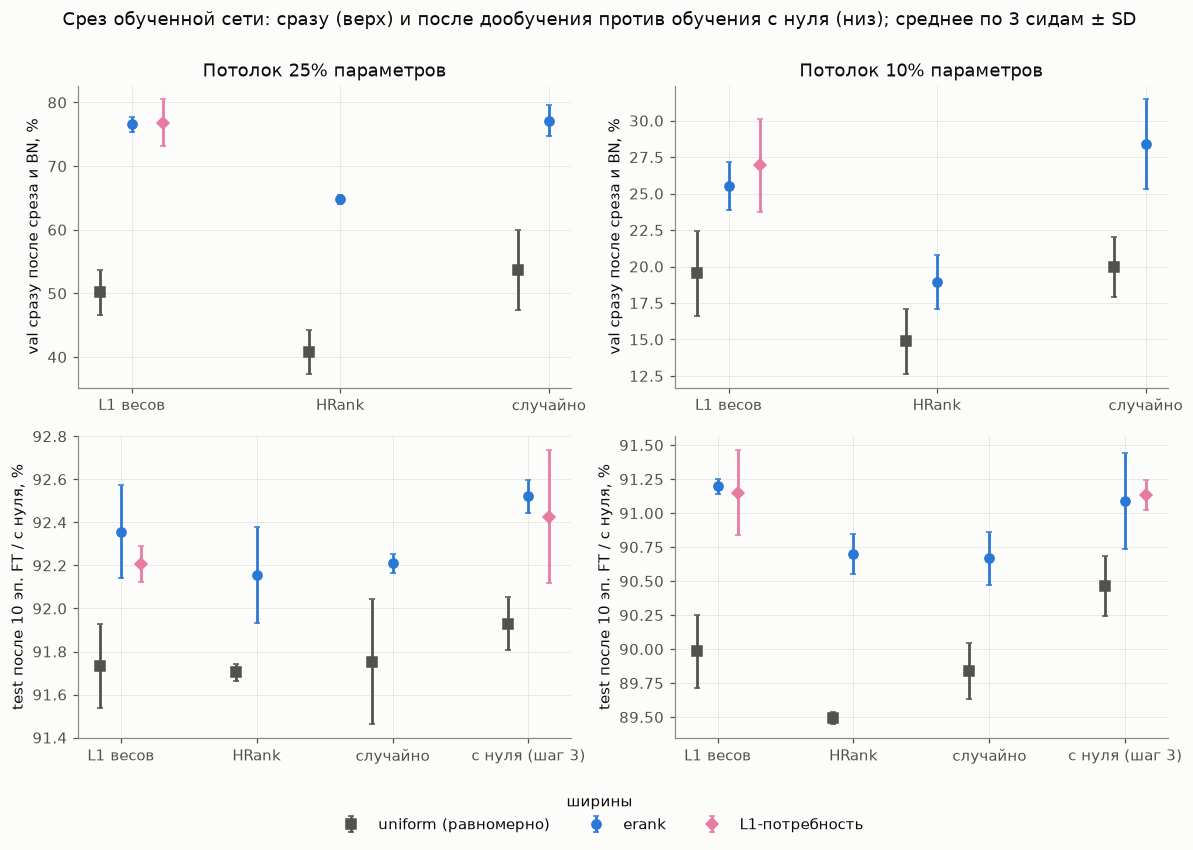

**Вывод.** Сразу после L1-среза (val): 25% — erank 76,5% против uniform 50,2%; 10% — erank 25,5% против uniform 19,5%. FT − с нуля (L1, test, п.п. [t95]): uniform (равномерно) 25%: −0,20 [−0,47; +0,08] (n=3) — разница не отличима от нуля при n=3; erank 25%: −0,16 [−0,58; +0,26] (n=3) — разница не отличима от нуля при n=3; uniform (равномерно) 10%: −0,48 [−0,95; −0,01] (n=3) — ниже обучения с нуля; erank 10%: +0,11 [−0,67; +0,89] (n=3) — разница не отличима от нуля при n=3. Вся таблица: срез + FT ниже тех же ширин с нуля в 35 из 42 пар «сид × потолок × ширины × выбор каналов»; интервал t95 ниже нуля в 4, выше нуля в 0 из 14 сочетаний «потолок × ширины × выбор» (n=3). Сравнение включает разницу эпох (10 FT после базы против 30 с нуля).

In [32]:
out = []
FT_GROUPS = {}  # (budget, method, select) -> paired summary of FT - scratch, p.p.
for budget in PARAM_BUDGETS:
    for method in FT_METHODS + ["need"]:
        for select in (FT_SELECT if method != "need" else ["l1"]):
            sel = by(FT, method=method, budget=budget, select=select)
            FT_GROUPS[(budget, method, select)] = paired_summary(
                [100 * (r["test_acc"] - r["scratch_test_acc"]) for r in sel])
            out.append({"потолок": budget_label("params", budget), "ширины": LABELS[method],
                        "выбор каналов": SELECT_LABELS[select],
                        "val сразу после среза, %": round(100 * np.mean([r["val_acc_before_ft"] for r in sel]), 2),
                        "test после FT, %": round(100 * np.mean([r["test_acc"] for r in sel]), 2),
                        "test с нуля, %": round(100 * np.mean([r["scratch_test_acc"] for r in sel]), 2),
                        "FT − с нуля, п.п. [t95]": ci_text(FT_GROUPS[(budget, method, select)])})
display(pd.DataFrame(out))

fig, axes = plt.subplots(2, len(PARAM_BUDGETS), figsize=(11, 7), squeeze=False)
for col, budget in enumerate(PARAM_BUDGETS):
    for row_i, (key, cats, ylabel) in enumerate([
            ("val_acc_before_ft", FT_SELECT, "val сразу после среза и BN, %"),
            ("test_acc", FT_SELECT + ["scratch"], f"test после {FT_EPOCHS} эп. FT / с нуля, %")]):
        ax = axes[row_i][col]
        for k, method in enumerate(FT_METHODS + ["need"]):
            st = style(method)
            xs, ys, es = [], [], []
            for c, cat in enumerate(cats):
                select = "l1" if cat == "scratch" else cat
                sel = by(FT, method=method, budget=budget, select=select)
                if not sel:
                    continue
                vals = [100 * r["scratch_test_acc" if cat == "scratch" else key] for r in sel]
                xs.append(c + (k - 1) * 0.15)
                ys.append(np.mean(vals))
                es.append(sd(vals))
            ax.errorbar(xs, ys, yerr=es, color=st["color"], marker=st["marker"], ls="none", capsize=2, ms=6,
                        label=st["label"])
        ax.set_xticks(range(len(cats)), [SELECT_LABELS[c] for c in cats])
        ax.set_ylabel(ylabel)
        if row_i == 0:
            ax.set_title(f"Потолок {budget:.0%} параметров")
fig.suptitle(f"Срез обученной сети: сразу (верх) и после дообучения против обучения с нуля (низ); "
             f"среднее по {len(SEEDS)} сидам ± SD", y=1.0)
plt.tight_layout()
fig.legend(*axes[0][0].get_legend_handles_labels(), title="ширины", loc="upper center", bbox_to_anchor=(0.5, 0.0),
           ncol=3)
plt.show()

FT_SUMMARY = {(m, b): paired_summary([100 * (r["test_acc"] - r["scratch_test_acc"])
                                      for r in by(FT, method=m, budget=b, select="l1")])
              for m in FT_METHODS + ["need"] for b in PARAM_BUDGETS}
cut = {(m, b): 100 * np.mean([r["val_acc_before_ft"] for r in by(FT, method=m, budget=b, select="l1")])
       for m in FT_METHODS for b in PARAM_BUDGETS}
FT_L1_TEXT = "; ".join(f"{LABELS[m]} {b:.0%}: {ci_text(FT_SUMMARY[(m, b)])} — "
                       f"{verdict(FT_SUMMARY[(m, b)], 'обучения с нуля')}" for b in PARAM_BUDGETS for m in FT_METHODS)
ft_d = [r["test_acc"] - r["scratch_test_acc"] for r in FT]  # every seed x budget x widths x selection
ft_ci = [s for s in FT_GROUPS.values() if s["ci95_pp"] is not None]
FT_COUNT_TEXT = (
    f"срез + FT ниже тех же ширин с нуля в {sum(x < 0 for x in ft_d)} из {len(ft_d)} пар «сид × потолок × ширины × "
    f"выбор каналов»; " + (
        f"интервал t95 ниже нуля в {sum(s['ci95_pp'][1] < 0 for s in ft_ci)}, выше нуля в "
        f"{sum(s['ci95_pp'][0] > 0 for s in ft_ci)} из {len(ft_ci)} сочетаний «потолок × ширины × выбор» "
        f"(n={'/'.join(str(n) for n in sorted({s['n'] for s in ft_ci}))})" if ft_ci else
        f"интервалы при n={len(SEEDS)} не определены"))
display(Markdown(
    "**Вывод.** Сразу после L1-среза (val): " + "; ".join(
        f"{b:.0%} — erank {num(cut[('erank', b)], 1)}% против uniform {num(cut[('uniform', b)], 1)}%"
        for b in PARAM_BUDGETS)
    + f". FT − с нуля (L1, test, п.п. [t95]): {FT_L1_TEXT}. Вся таблица: {FT_COUNT_TEXT}. "
    f"Сравнение включает разницу эпох ({FT_EPOCHS} FT после базы против {EPOCHS} с нуля)."))

## Шаг 5. Итерации: сходится ли процедура к стабильной архитектуре

(a) Протокол основной серии при постоянном потолке 25% параметров: erank сети предыдущего раунда → новые ширины →
обучение с нуля → erank новой сети. Первый раунд совпадает с erank-сетью шага 3. Сходимость — среднее
|Δширины| / ширина между соседними раундами; порог «ширины стабильны», последнее изменение < 5%, условный.

In [33]:
ITER_A = []
for seed in SEEDS:
    base = BASES[seed]
    target = int(ITER_BUDGET * count_params(base))
    eranks = inner(BASE_ROWS[seed]["layers"], "erank_energy")
    for r in range(1, ITER_ROUNDS + 1):
        widths = fit_budget(eranks, target, base)
        row = scratch(widths, seed)
        ITER_A.append({"round": r, "seed": seed, "widths": widths, "test_acc": row["test_acc"],
                       "params": row["params"], "macs": row["macs"]})
        eranks = inner(row["layers"], "erank_energy")  # the next round allocates by the new network's erank
    log(f"Шаг 5a: сид {seed} готов")
free()

Шаг 5a: сид 0 готов


Шаг 5a: сид 1 готов


Шаг 5a: сид 2 готов


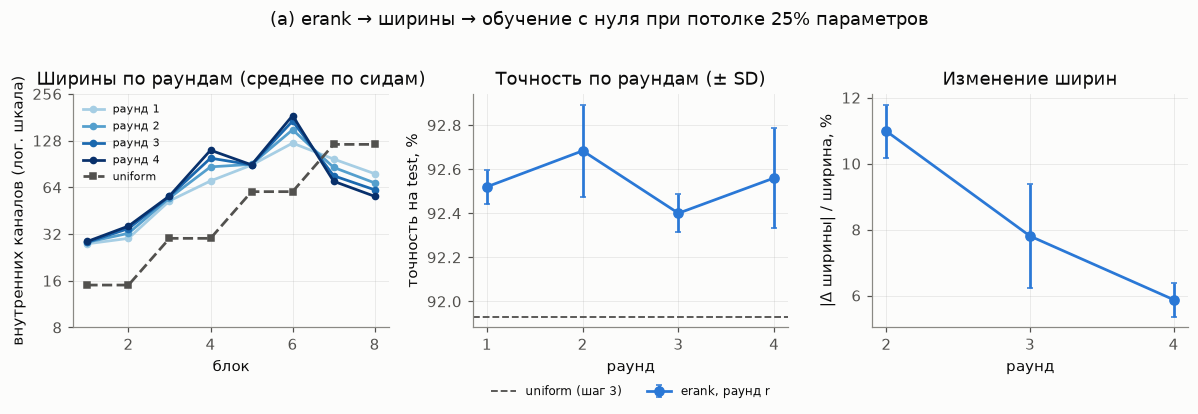

**Вывод.** Изменение ширин между раундами: 11,0% → 7,8% → 5,9% — убывает от каждого раунда к следующему; стабильной архитектуры за 4 раунда не видно (последнее изменение ≥ 5%; порог условный). Раунд 4 против раунда 1: |Δширины| / ширина в среднем 24,8%; блоки 4, 6, 7, 8 сдвигаются в одну сторону в каждом раунде у всех сидов. Test по раундам: 92,52 → 92,68 → 92,40 → 92,56%; раунд 4 − раунд 1: +0,04 [−0,47; +0,55] (n=3) п.п. (разница не отличима от нуля при n=3).

In [34]:
def change(rows, r):
    """Mean over seeds of the mean |w_r - w_{r-1}| / w_{r-1} over blocks, in %."""
    per_seed = []
    for s in SEEDS:
        a, b = by(rows, seed=s, round=r - 1)[0]["widths"], by(rows, seed=s, round=r)[0]["widths"]
        per_seed.append(100 * np.mean([abs(y - x) / x for x, y in zip(a, b)]))
    return per_seed


rounds = list(range(1, ITER_ROUNDS + 1))
round_colors = plt.cm.Blues(np.linspace(0.35, 1.0, len(rounds)))
uni_w = np.mean([r["inner_widths"] for r in by(ALLOC, measure="params", budget=ITER_BUDGET, method="uniform")], 0) \
    if by(ALLOC, measure="params", budget=ITER_BUDGET, method="uniform") else None
uni_acc = [100 * r["test_acc"] for r in by(ALLOC, measure="params", budget=ITER_BUDGET, method="uniform")]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.8))
for r, color in zip(rounds, round_colors):
    axes[0].plot(list(blocks), np.mean([x["widths"] for x in by(ITER_A, round=r)], 0), color=color, marker="o",
                 ms=4, label=f"раунд {r}")
if uni_w is not None:
    axes[0].plot(list(blocks), uni_w, color=PALETTE["uniform"], ls="--", marker=MARKERS["uniform"], ms=4,
                 label="uniform")
log2_axis(axes[0], [x["widths"] for x in ITER_A] + ([list(uni_w)] if uni_w is not None else []))
axes[0].set_xlabel("блок")
axes[0].set_ylabel("внутренних каналов (лог. шкала)")
axes[0].set_title("Ширины по раундам (среднее по сидам)")
axes[0].legend(fontsize=7)
acc_r = [[100 * x["test_acc"] for x in by(ITER_A, round=r)] for r in rounds]
axes[1].errorbar(rounds, [np.mean(a) for a in acc_r], yerr=[sd(a) for a in acc_r], color=PALETTE["erank"],
                 marker="o", capsize=2, label="erank, раунд r")
if uni_acc:
    axes[1].axhline(np.mean(uni_acc), color=PALETTE["uniform"], ls="--", lw=1.2, label="uniform (шаг 3)")
axes[1].set_xticks(rounds)
axes[1].set_xlabel("раунд")
axes[1].set_ylabel("точность на test, %")
axes[1].set_title("Точность по раундам (± SD)")
axes[1].legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ch = [change(ITER_A, r) for r in rounds[1:]]
axes[2].errorbar(rounds[1:], [np.mean(c) for c in ch], yerr=[sd(c) for c in ch], color=PALETTE["erank"],
                 marker="o", capsize=2)
axes[2].set_xticks(rounds[1:])
axes[2].set_xlabel("раунд")
axes[2].set_ylabel("|Δ ширины| / ширина, %")
axes[2].set_title("Изменение ширин")
fig.suptitle(f"(a) erank → ширины → обучение с нуля при потолке {ITER_BUDGET:.0%} параметров", y=1.02)
plt.tight_layout()
plt.show()

last_vs_first = paired_summary([100 * (by(ITER_A, seed=s, round=rounds[-1])[0]["test_acc"]
                                       - by(ITER_A, seed=s, round=1)[0]["test_acc"]) for s in SEEDS])
ch_mean = [float(np.mean(c)) for c in ch]
chain = " → ".join(f"{num(c, 1)}%" for c in ch_mean)
if len(ch_mean) < 2:
    shrinking = "одно изменение, убывание по раундам не проверить"
elif all(b < a for a, b in zip(ch_mean, ch_mean[1:])):
    shrinking = "убывает от каждого раунда к следующему"
else:
    shrinking = "убывает не от каждого раунда к следующему"


def rounds_word(n: int) -> str:
    """'раунд' / 'раунда' / 'раундов' after the number n."""
    if n % 10 == 1 and n % 100 != 11:
        return "раунд"
    return "раунда" if 2 <= n % 10 <= 4 and not 12 <= n % 100 <= 14 else "раундов"


# the same conditional threshold as the ViT notebook: the last change below 5% counts as stable widths
if not ch_mean:
    stable = "сходимость по одному раунду не проверить"
elif ch_mean[-1] < 5:
    stable = "ширины близки к стабильным (последнее изменение < 5%; порог условный)"
else:
    stable = (f"стабильной архитектуры за {rounds[-1]} {rounds_word(rounds[-1])} не видно (последнее изменение ≥ 5%; "
              "порог условный)")
drift_text = ""
if len(rounds) > 1:
    drift = float(np.mean([100 * np.mean([abs(y - x) / x for x, y in zip(
        by(ITER_A, seed=s, round=1)[0]["widths"], by(ITER_A, seed=s, round=rounds[-1])[0]["widths"])]) for s in SEEDS]))
    drift_text = f"раунд {rounds[-1]} против раунда 1: |Δширины| / ширина в среднем {num(drift, 1)}%"
if len(rounds) > 2:  # seeds x round steps x blocks: the sign of every round's change
    steps = np.array([np.sign(np.diff([by(ITER_A, seed=s, round=r)[0]["widths"] for r in rounds], axis=0))
                      for s in SEEDS])
    mono = [b for b in blocks if np.all(steps[:, :, b - 1] > 0) or np.all(steps[:, :, b - 1] < 0)]
    drift_text += ("; ни один блок не сдвигается в одну сторону в каждом раунде у всех сидов" if not mono else
                   f"; блок{'и' if len(mono) > 1 else ''} {', '.join(map(str, mono))} "
                   f"сдвига{'ются' if len(mono) > 1 else 'ется'} в одну сторону в каждом раунде у всех сидов")
display(Markdown(
    f"**Вывод.** Изменение ширин между раундами: {chain} — {shrinking}; {stable}. "
    + (f"{drift_text[:1].upper()}{drift_text[1:]}. " if drift_text else "")
    + f"Test по раундам: {' → '.join(num(np.mean(a)) for a in acc_r)}%; раунд {rounds[-1]} − раунд 1: "
    f"{ci_text(last_vs_first)} п.п. ({verdict(last_vs_first, 'раунда 1')})."))

(b) Буквальный цикл «повторить шаги 2–4» с уменьшающимся потолком 50% → 25% → 10% параметров: erank дообученной
сети предыдущего раунда → ширины (не шире прежних) → L1-срез этой сети → BN → 10 эпох дообучения; те же ширины
обучаются и с нуля.

In [35]:
ITER_B = []
for seed in SEEDS:
    prev, prev_layers = BASES[seed], BASE_ROWS[seed]["layers"]
    full_params = count_params(BASES[seed])
    for r, budget in enumerate(PROGRESSIVE, 1):
        # fit_budget on the previous network: its widths are the caps, the sizes are those of the same ResNet
        widths = fit_budget(inner(prev_layers, "erank_energy"), int(budget * full_params), prev)

        def cut_and_finetune():
            model = keep_inner(prev, [top_k(s, w) for s, w in zip(channel_scores(prev, "l1"), widths)])
            recalibrate_bn(model, data["x_train"][:BN_N])
            before = evaluate(model, data["x_val"], data["y_val"])["acc"]
            train(model, data, FT_EPOCHS, FT_LR, seed=seed, verbose=False, **TRAIN_KW)
            row = {"round": r, "budget": budget, "seed": seed, "widths": widths, "val_acc_before_ft": before,
                   "test_acc": evaluate(model, data["x_test"], data["y_test"])["acc"],
                   "layers": layer_metrics(model, data["x_val"]), **describe(model)}
            log(f"  итерация (b) s{seed} раунд {r}: {before:.4f} -> {row['test_acc']:.4f}", show=False)
            return model, row

        # the widths are part of the id: a round reloaded from the cache always continues the same chain of cuts
        model, row = cached_net(f"iterft|{TAG}|r{r}|{budget}|w={widths}|s{seed}|e{EPOCHS}|ft{FT_EPOCHS}",
                                cut_and_finetune)
        ITER_B.append({**{k: row[k] for k in ["round", "budget", "seed", "widths", "val_acc_before_ft", "test_acc",
                                              "params", "macs"]},
                       "scratch_test_acc": scratch(row["widths"], seed)["test_acc"]})  # the same widths from scratch
        prev, prev_layers = model, row["layers"]
    log(f"Шаг 5b: сид {seed} готов")
free()

Шаг 5b: сид 0 готов


Шаг 5b: сид 1 готов


Шаг 5b: сид 2 готов


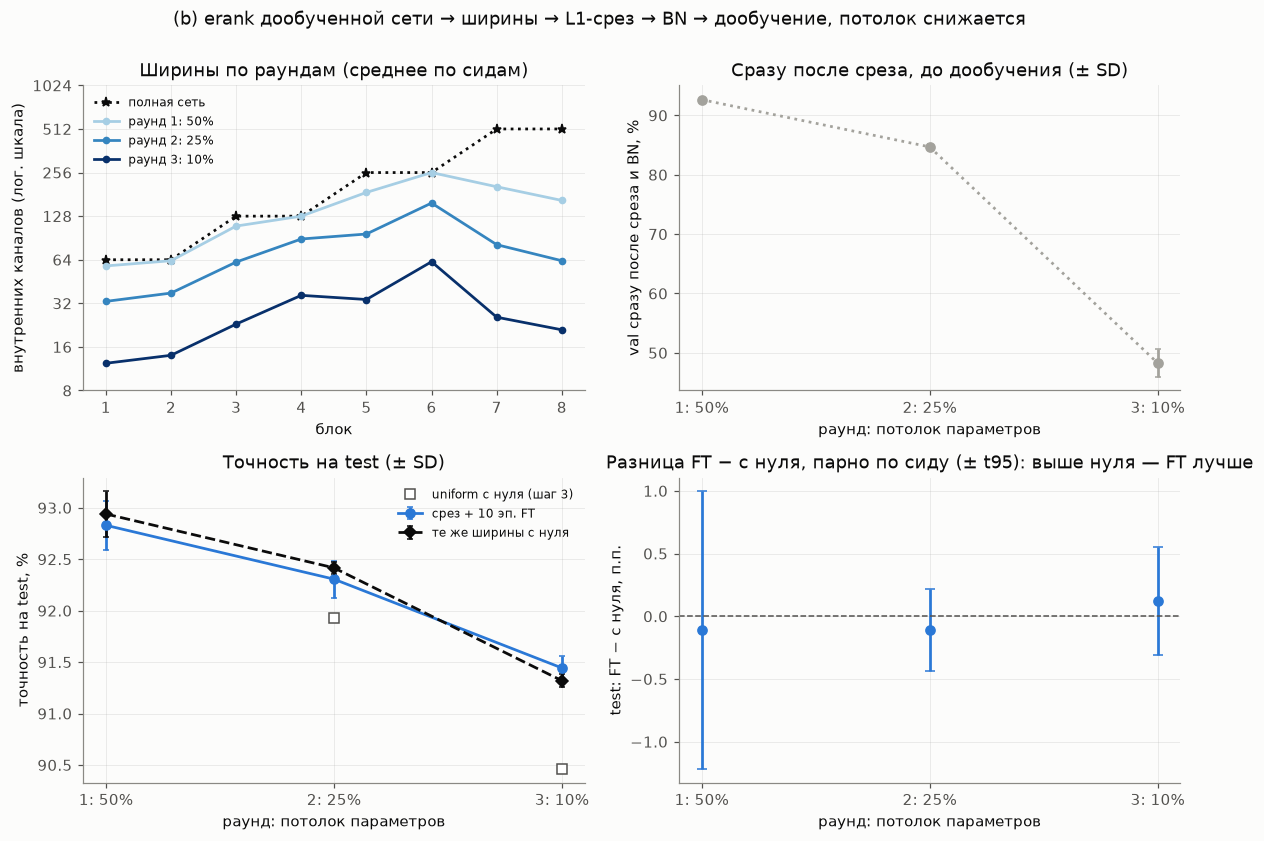

**Вывод.** FT − с нуля по раундам, п.п. [t95]: 50%: −0,11 [−1,22; +1,00] (n=3), разница не отличима от нуля при n=3; 25%: −0,11 [−0,43; +0,21] (n=3), разница не отличима от нуля при n=3; 10%: +0,12 [−0,31; +0,55] (n=3), разница не отличима от нуля при n=3. Ширины последнего раунда (сид 0): 12, 15, 23, 35, 34, 63, 27, 20.

In [36]:
rounds_b = list(range(1, len(PROGRESSIVE) + 1))
colors_b = plt.cm.Blues(np.linspace(0.35, 1.0, len(rounds_b)))
round_ticks = (rounds_b, [f"{r}: {b:.0%}" for r, b in zip(rounds_b, PROGRESSIVE)])
gap = {r: paired_summary([100 * (x["test_acc"] - x["scratch_test_acc"]) for x in by(ITER_B, round=r)])
       for r in rounds_b}
fig, axes = plt.subplots(2, 2, figsize=(11, 7.6))
ax = axes[0][0]
ax.plot(list(blocks), BASES[SEEDS[0]].inner_widths(), color="#0b0b0b", ls=":", marker="*", ms=6, label="полная сеть")
for r, color in zip(rounds_b, colors_b):
    ax.plot(list(blocks), np.mean([x["widths"] for x in by(ITER_B, round=r)], 0), color=color, marker="o",
            ms=4, label=f"раунд {r}: {PROGRESSIVE[r - 1]:.0%}")
log2_axis(ax, [BASES[SEEDS[0]].inner_widths()] + [x["widths"] for x in ITER_B])
ax.set_xlabel("блок")
ax.set_ylabel("внутренних каналов (лог. шкала)")
ax.set_title("Ширины по раундам (среднее по сидам)")
ax.legend(fontsize=8)

ax = axes[0][1]  # the cut alone: its own axis, it is far below the trained accuracies
vals = [[100 * x["val_acc_before_ft"] for x in by(ITER_B, round=r)] for r in rounds_b]
ax.errorbar(rounds_b, [np.mean(a) for a in vals], yerr=[sd(a) for a in vals], color=PALETTE["random"], marker="o",
            ls=":", capsize=2)
ax.set_xticks(*round_ticks)
ax.set_xlabel("раунд: потолок параметров")
ax.set_ylabel("val сразу после среза и BN, %")
ax.set_title("Сразу после среза, до дообучения (± SD)")

ax = axes[1][0]
for key, label, color, marker, ls in [("test_acc", f"срез + {FT_EPOCHS} эп. FT", PALETTE["erank"], "o", "-"),
                                      ("scratch_test_acc", "те же ширины с нуля", "#0b0b0b", "D", "--")]:
    vals = [[100 * x[key] for x in by(ITER_B, round=r)] for r in rounds_b]
    ax.errorbar(rounds_b, [np.mean(a) for a in vals], yerr=[sd(a) for a in vals], color=color, marker=marker,
                ls=ls, capsize=2, label=label)
uni = [(r, [100 * x["test_acc"] for x in by(ALLOC, measure="params", budget=b, method="uniform")])
       for r, b in zip(rounds_b, PROGRESSIVE)]
uni = [(r, a) for r, a in uni if a]
if uni:
    ax.plot([r for r, _ in uni], [np.mean(a) for _, a in uni], color=PALETTE["uniform"], marker=MARKERS["uniform"],
            ls="none", mfc="white", ms=7, label="uniform с нуля (шаг 3)")
ax.set_xticks(*round_ticks)
ax.set_xlabel("раунд: потолок параметров")
ax.set_ylabel("точность на test, %")
ax.set_title("Точность на test (± SD)")
ax.legend(fontsize=8)

ax = axes[1][1]
means = [gap[r]["mean_pp"] for r in rounds_b]
err = None if any(gap[r]["ci95_pp"] is None for r in rounds_b) else \
    [[gap[r]["mean_pp"] - gap[r]["ci95_pp"][0] for r in rounds_b], [gap[r]["ci95_pp"][1] - gap[r]["mean_pp"] for r in rounds_b]]
ax.errorbar(rounds_b, means, yerr=err, color=PALETTE["erank"], marker="o", ls="none", capsize=3)
ax.axhline(0, color=PALETTE["uniform"], ls="--", lw=1)
ax.set_xticks(*round_ticks)
ax.set_xlabel("раунд: потолок параметров")
ax.set_ylabel("test: FT − с нуля, п.п.")
ax.set_title("Разница FT − с нуля, парно по сиду (± t95): выше нуля — FT лучше")
fig.suptitle("(b) erank дообученной сети → ширины → L1-срез → BN → дообучение, потолок снижается", y=1.0)
plt.tight_layout()
plt.show()

display(Markdown(
    "**Вывод.** FT − с нуля по раундам, п.п. [t95]: " + "; ".join(
        f"{PROGRESSIVE[r - 1]:.0%}: {ci_text(gap[r])}, {verdict(gap[r], 'обучения с нуля')}" for r in rounds_b)
    + ". Ширины последнего раунда (сид " + str(SEEDS[0]) + "): "
    + ", ".join(str(w) for w in by(ITER_B, seed=SEEDS[0], round=rounds_b[-1])[0]["widths"]) + "."))

## Размер, MACs и время инференса

Время одного батча на случайных весах (от весов оно не зависит): CPU float32, 4 потока, батч 32 и батч 1; GPU
bfloat16, батч 512; 5 прогревов, медиана 30 повторов (батч 1 — 100). Сети: полная, все архитектуры шага 3 сида 0 и
low-rank ×1 erank. Число потоков восстанавливается после замера. Вычисления считаются в MACs (FLOPs ≈ 2·MACs).
Абсолютные миллисекунды CPU зависят от окружения и могут заметно различаться между процессами и сессиями, поэтому
сравниваются отношения времён и Spearman(MACs, время), а не сами миллисекунды.

In [37]:
LAT = {}
threads_before = torch.get_num_threads()
torch.set_num_threads(CPU_THREADS)
try:
    def timing(model):
        model = model.to(DEVICE)
        row = {"params": count_params(model), "macs": count_macs(model), "cpu_threads": torch.get_num_threads(),
               "gpu_ms_batch512": latency_ms(model, DEVICE, 512, LAT_REPEATS) if DEVICE == "cuda" else None}
        row["cpu_ms_batch32"] = latency_ms(model.cpu(), "cpu", 32, LAT_REPEATS)
        row["cpu_ms_batch1"] = latency_ms(model, "cpu", 1, LAT_REPEATS_B1)
        return row

    s0 = SEEDS[0]
    LAT["full"] = cached(f"lat|{TAG}|full|r{LAT_REPEATS}", lambda: timing(new_model()))
    for r in by(ALLOC, seed=s0):
        key = f"w={r['inner_widths']}"
        if key not in LAT:
            LAT[key] = cached(f"lat|{TAG}|{key}|r{LAT_REPEATS}", lambda: timing(new_model(r["inner_widths"])))
    ranks1 = [min(w, max(4, round(e))) for e, w in zip(inner(BASE_ROWS[s0]["layers"], "erank_energy"),
                                                       BASES[s0].inner_widths())]
    for basis in ["pca", "svd"]:
        LAT[f"lowrank|{basis}"] = cached(
            f"lat|{TAG}|lowrank|{basis}|1|s{s0}|r{LAT_REPEATS}",
            lambda: timing(lowrank_conv2(BASES[s0], ranks1, data["x_val"][:1000], basis=basis)))
finally:
    torch.set_num_threads(threads_before)
free()
print(f"замерено {len(LAT)} архитектур; потоков CPU после замера: {torch.get_num_threads()}")

замерено 37 архитектур; потоков CPU после замера: 8


,сеть,потолок,"test, %","params, млн","MACs, млн","CPU батч 32, мс","CPU батч 1, мс","GPU батч 512, мс"
0,полная,—,92.81,11.17,555.42,61.20,6.06,13.91
1,uniform (равномерно),25% параметров,91.93,2.78,136.61,19.37,2.78,7.75
2,random (случайно),25% параметров,91.50,2.77,115.23,19.21,2.59,7.86
3,erank,25% параметров,92.52,2.77,218.49,29.34,3.03,9.26
4,Taylor (глобально),25% параметров,92.97,2.79,403.28,46.30,3.31,12.39
5,|γ| BN (глобально),25% параметров,92.13,2.79,168.54,23.88,2.79,10.54
6,"Network Slimming (λ=0,001)",25% параметров,92.76,2.79,291.14,38.19,3.20,10.96
7,L1-потребность,25% параметров,92.43,2.78,230.47,28.80,2.90,9.42
8,erank / цена канала,25% параметров,92.79,2.79,372.98,43.12,3.32,11.97
9,только цена канала,25% параметров,92.80,2.79,368.89,42.51,2.90,11.82


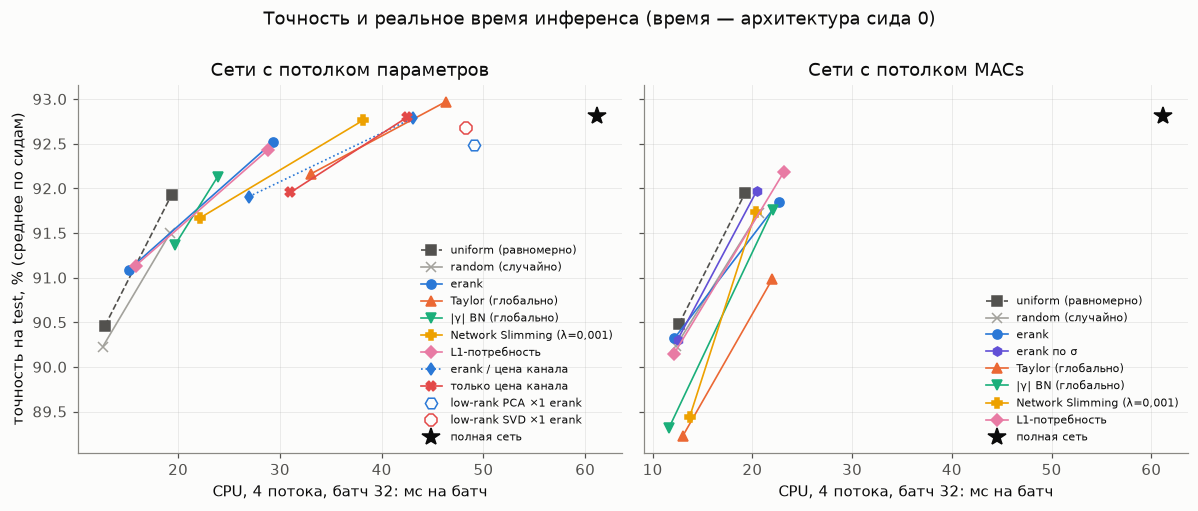

**Вывод.** Spearman(MACs, время) по 37 архитектурам: CPU батч 32 ρ = 0,98, CPU батч 1 ρ = 0,89, GPU батч 512 ρ = 0,95; Spearman(параметры, время): CPU батч 32 ρ = 0,75, CPU батч 1 ρ = 0,89, GPU батч 512 ρ = 0,76.

In [38]:
out = [{"сеть": "полная", "потолок": "—", "test, %": np.mean(FULL_ACC), **LAT["full"]}]
for measure, budgets, methods in [("params", PARAM_BUDGETS, PARAM_METHODS), ("macs", MAC_BUDGETS, MAC_METHODS)]:
    for budget in budgets:
        for method in methods:
            sel = by(ALLOC, measure=measure, budget=budget, method=method)
            w0 = by(sel, seed=SEEDS[0])[0]["inner_widths"]
            out.append({"сеть": LABELS[method], "потолок": budget_label(measure, budget),
                        "test, %": 100 * np.mean([r["test_acc"] for r in sel]), **LAT[f"w={w0}"]})
for basis in ["pca", "svd"]:
    out.append({"сеть": f"{LABELS[basis]} ×1 erank", "потолок": "—",
                "test, %": 100 * np.mean([r["test_acc"] for r in by(LOWRANK, basis=basis, mult=1)]),
                **LAT[f"lowrank|{basis}"]})
lat_df = pd.DataFrame(out)
lat_df["params, млн"] = lat_df["params"] / 1e6
lat_df["MACs, млн"] = lat_df["macs"] / 1e6
cols = ["сеть", "потолок", "test, %", "params, млн", "MACs, млн", "cpu_ms_batch32", "cpu_ms_batch1", "gpu_ms_batch512"]
display(lat_df[cols].rename(columns={"cpu_ms_batch32": "CPU батч 32, мс", "cpu_ms_batch1": "CPU батч 1, мс",
                                     "gpu_ms_batch512": "GPU батч 512, мс"}).round(2))

uniq = list(LAT.values())
RHO_LAT = {k: spearman([x["macs"] for x in uniq if x[k] is not None], [x[k] for x in uniq if x[k] is not None])
           for k in ["cpu_ms_batch32", "cpu_ms_batch1", "gpu_ms_batch512"] if any(x[k] is not None for x in uniq)}
RHO_LAT_P = {k: spearman([x["params"] for x in uniq if x[k] is not None], [x[k] for x in uniq if x[k] is not None])
             for k in RHO_LAT}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), sharey=True)
for ax, measure, budgets, methods in [(axes[0], "params", PARAM_BUDGETS, PARAM_METHODS),
                                      (axes[1], "macs", MAC_BUDGETS, MAC_METHODS)]:
    for method in methods:
        st = style(method)
        pts = []
        for budget in budgets:
            sel = by(ALLOC, measure=measure, budget=budget, method=method)
            w0 = by(sel, seed=SEEDS[0])[0]["inner_widths"]
            pts.append((LAT[f"w={w0}"]["cpu_ms_batch32"], 100 * np.mean([r["test_acc"] for r in sel])))
        xs, ys = zip(*sorted(pts))
        ax.plot(xs, ys, color=st["color"], marker=st["marker"], ls=st["ls"], lw=1.1, ms=6, label=st["label"])
    if measure == "params":
        for basis in ["pca", "svd"]:
            ax.plot(LAT[f"lowrank|{basis}"]["cpu_ms_batch32"],
                    100 * np.mean([r["test_acc"] for r in by(LOWRANK, basis=basis, mult=1)]),
                    color=PALETTE[basis], marker=MARKERS[basis], mfc="none", ls="none", ms=8,
                    label=f"{LABELS[basis]} ×1 erank")
    ax.plot(LAT["full"]["cpu_ms_batch32"], np.mean(FULL_ACC), color="#0b0b0b", marker="*", ms=12, ls="none",
            label="полная сеть")
    ax.set_xlabel(f"CPU, {CPU_THREADS} потока, батч 32: мс на батч")
    ax.set_title(f"Сети с потолком {RESOURCE[measure]}")
    ax.legend(fontsize=7, loc="lower right")
axes[0].set_ylabel("точность на test, % (среднее по сидам)")
fig.suptitle("Точность и реальное время инференса (время — архитектура сида 0)", y=1.0)
plt.tight_layout()
plt.show()
display(Markdown(
    f"**Вывод.** Spearman(MACs, время) по {len(uniq)} архитектурам: " + ", ".join(
        f"{k.replace('cpu_ms_batch', 'CPU батч ').replace('gpu_ms_batch', 'GPU батч ')} ρ = {num(v)}"
        for k, v in RHO_LAT.items())
    + "; Spearman(параметры, время): " + ", ".join(
        f"{k.replace('cpu_ms_batch', 'CPU батч ').replace('gpu_ms_batch', 'GPU батч ')} ρ = {num(v)}"
        for k, v in RHO_LAT_P.items()) + "."))

## Итог

Главная таблица — разница точности на test каждого метода с uniform при одном потолке, парная по сиду
(среднее [t95] (n), п.п.), и на скольких сидах метод выше uniform; ниже — вывод, посчитанный из этих чисел и из
шагов 2, 4, 5.

In [39]:
COLS = [(m, b) for m, bs in [("params", PARAM_BUDGETS), ("macs", MAC_BUDGETS)] for b in bs]
final = {}
for m, b in COLS:
    rows_mb = by(ALLOC, measure=m)
    shown = [method for method in methods_all if method != "uniform" and (m, b, method) in SUMMARY]
    final[(budget_label(m, b), "Δ к uniform, п.п. [t95] (n)")] = {
        **{LABELS[method]: ci_text(SUMMARY[(m, b, method)]) for method in shown},
        "uniform: test, %": num(100 * np.mean([r["test_acc"] for r in by(rows_mb, budget=b, method="uniform")]))}
    final[(budget_label(m, b), "выше uniform, сидов")] = {
        LABELS[method]: seeds_better(paired_diffs(rows_mb, method, b)) for method in shown}
index = [LABELS[method] for method in methods_all if method != "uniform"] + ["uniform: test, %"]
display(pd.DataFrame(final, index=index).fillna("—"))


def vs_erank(measure, budget, method):
    """Paired summary of method - erank (same seed and budget), p.p."""
    rows = by(ALLOC, measure=measure, budget=budget)
    e = {r["seed"]: r["test_acc"] for r in by(rows, method="erank")}
    return paired_summary([100 * (r["test_acc"] - e[r["seed"]]) for r in by(rows, method=method) if r["seed"] in e])


def resource_phrase(measure):
    """erank against uniform for every budget of one resource, then the method with the largest mean difference."""
    cols = [(m, b) for m, b in COLS if m == measure]
    v = [verdict(SUMMARY[(m, b, "erank")]) for m, b in cols]
    up = [budget_label(m, b) for (m, b), x in zip(cols, v) if x.startswith("выше")]
    down = [budget_label(m, b) for (m, b), x in zip(cols, v) if x.startswith("ниже")]
    rest = [budget_label(m, b) for (m, b), x in zip(cols, v) if not x.startswith(("выше", "ниже"))]
    n = len(SEEDS)
    if n < 2:
        head = ("интервалы при n=1 не определены; erank − uniform: "
                + ", ".join(f"{budget_label(m, b)} {num(mean_delta(m, b, 'erank'), 2, True)}" for m, b in cols))
    elif not up and not down:
        head = f"разница erank с uniform не отличима от нуля ни в одном из {len(cols)} бюджетов (n={n})"
    else:
        head = "erank " + "; ".join(([f"выше uniform при {', '.join(up)}"] if up else [])
                                    + ([f"ниже uniform при {', '.join(down)}"] if down else []))
        head += f"; при {', '.join(rest)} разница не отличима от нуля (n={n})" if rest else f" (n={n})"
    tails = []
    for m, b in cols:
        w, e = best_by[(m, b)], mean_delta(m, b, "erank")
        if w == "uniform":
            tails.append(f"{budget_label(m, b)} — ни один метод не выше uniform (erank {num(e, 2, True)})")
        elif w == "erank":
            tails.append(f"{budget_label(m, b)} — erank ({num(e, 2, True)})")
        else:
            tails.append(f"{budget_label(m, b)} — {LABELS[w]} ({num(mean_delta(m, b, w), 2, True)}; "
                         f"{LABELS[w]} − erank {ci_text(vs_erank(m, b, w))})")
    return head + ". Наибольшая средняя разница с uniform: " + "; ".join(tails)


def cap(text: str) -> str:
    """Capital first letter of a sentence (erank keeps its lower case)."""
    return text if text.startswith("erank") else text[:1].upper() + text[1:]


op_text = (f"потребность зависит от операции: L1-срезу нужно {num(ratio['prune'])}×erank каналов, PCA — "
           f"{num(ratio['pca'])}×erank направлений" if max(ratio.values()) > 1.5 * min(ratio.values()) else
           f"L1-срезу и PCA нужно близкое число направлений: {num(ratio['prune'])}× и {num(ratio['pca'])}×erank")
display(Markdown("\n".join([
    f"**Ответ для {NET_NAME} (сидов: {len(SEEDS)}, эпох: {EPOCHS}).**",
    "",
    f"- **Сжимаемость слоя (шаг 2).** erank упорядочивает блоки как потребность L1-среза с ρ = "
    f"{num(RHO['prune']['erank_energy'])} (лучшая мера — {MEASURE_LABELS[best('prune')]}, ρ = "
    f"{num(RHO['prune'][best('prune')])}; ширина блока {num(RHO['prune']['width'])}); {op_text}. Ближе всего к erank "
    f"потребность L1 в блоке {close_b} ({num(block_ratio['prune'][close_b - 1])}×erank), дальше всего — в блоке "
    f"{far_b} ({num(block_ratio['prune'][far_b - 1])}×erank).",
    f"- **Правило ширин, потолок параметров (шаг 3).** {cap(resource_phrase('params'))}.",
    f"- **Правило ширин, потолок MACs (шаг 3).** {cap(resource_phrase('macs'))}.",
    f"- **Дообучение среза против обучения с нуля (шаг 4, выбор по L1, FT − с нуля, п.п.).** {FT_L1_TEXT}. "
    f"Вся таблица шага 4: {FT_COUNT_TEXT}.",
    f"- **Итерации (шаг 5a, {ITER_BUDGET:.0%} параметров).** Изменение ширин между раундами {chain} — {shrinking}; "
    f"{stable}" + (f"; {drift_text}" if drift_text else "")
    + f"; последний раунд − первый {ci_text(last_vs_first)} п.п. ({verdict(last_vs_first, 'раунда 1')}).",
    "",
    "Интервалы — обычный t95 по сидам без поправки на множественные сравнения; пересечение нуля не означает "
    "эквивалентности."])))

25% параметров                      \
                           Δ к uniform, п.п. [t95] (n) выше uniform, сидов   
random (случайно)           −0,43 [−1,13; +0,26] (n=3)                 0/3   
erank                       +0,59 [+0,48; +0,70] (n=3)                 3/3   
Taylor (глобально)          +1,04 [+0,51; +1,57] (n=3)                 3/3   
|γ| BN (глобально)          +0,20 [−0,49; +0,89] (n=3)                 2/3   
Network Slimming (λ=0,001)  +0,83 [+0,35; +1,32] (n=3)                 3/3   
L1-потребность              +0,50 [−0,48; +1,47] (n=3)                 3/3   
erank / цена канала         +0,86 [+0,26; +1,46] (n=3)                 3/3   
только цена канала          +0,87 [+0,51; +1,23] (n=3)                 3/3   
erank по σ                                           —                   —   
uniform: test, %                                 91,93                   —   

                                        10% параметров                      \
                           Δ к uniform, п.п. [t95] (n) выше uniform, сидов   
random (случайно)           −0,24 [−2,04; +1,57] (n=3)                 1/3   
erank                       +0,62 [−0,80; +2,05] (n=3)                 2/3   
Taylor (глобально)          +1,70 [+0,92; +2,48] (n=3)                 3/3   
|γ| BN (глобально)          +0,91 [+0,34; +1,47] (n=3)                 3/3   
Network Slimming (λ=0,001)  +1,21 [+0,54; +1,87] (n=3)                 3/3   
L1-потребность              +0,67 [+0,12; +1,22] (n=3)                 3/3   
erank / цена канала         +1,44 [+0,68; +2,20] (n=3)                 3/3   
только цена канала          +1,49 [+0,74; +2,24] (n=3)                 3/3   
erank по σ                                           —                   —   
uniform: test, %                                 90,46                   —   

                                              25% MACs                      \
                           Δ к uniform, п.п. [t95] (n) выше uniform, сидов   
random (случайно)           −0,23 [−1,13; +0,67] (n=3)                 1/3   
erank                       −0,10 [−0,29; +0,09] (n=3)                 0/3   
Taylor (глобально)          −0,97 [−1,66; −0,27] (n=3)                 0/3   
|γ| BN (глобально)          −0,19 [−0,64; +0,26] (n=3)                 0/3   
Network Slimming (λ=0,001)  −0,21 [−0,80; +0,38] (n=3)                 1/3   
L1-потребность              +0,23 [+0,03; +0,43] (n=3)                 3/3   
erank / цена канала                                  —                   —   
только цена канала                                   —                   —   
erank по σ                  +0,02 [−0,60; +0,64] (n=3)                 2/3   
uniform: test, %                                 91,95                   —   

                                              10% MACs                      
                           Δ к uniform, п.п. [t95] (n) выше uniform, сидов  
random (случайно)           −0,25 [−0,45; −0,04] (n=3)                 0/3  
erank                       −0,16 [−1,15; +0,83] (n=3)                 1/3  
Taylor (глобально)          −1,26 [−1,94; −0,57] (n=3)                 0/3  
|γ| BN (глобально)          −1,17 [−1,93; −0,42] (n=3)                 0/3  
Network Slimming (λ=0,001)  −1,05 [−1,51; −0,59] (n=3)                 0/3  
L1-потребность              −0,34 [−0,72; +0,05] (n=3)                 0/3  
erank / цена канала                                  —                   —  
только цена канала                                   —                   —  
erank по σ                  −0,18 [−1,00; +0,64] (n=3)                 1/3  
uniform: test, %                                 90,48                   —

**Ответ для ResNet-18 / CIFAR-10 (сидов: 3, эпох: 30).**

- **Сжимаемость слоя (шаг 2).** erank упорядочивает блоки как потребность L1-среза с ρ = 0,94 (лучшая мера — erank (λ), после ReLU, ρ = 0,94; ширина блока 0,76); потребность зависит от операции: L1-срезу нужно 0,95×erank каналов, PCA — 0,30×erank направлений. Ближе всего к erank потребность L1 в блоке 1 (0,95×erank), дальше всего — в блоке 8 (0,80×erank).
- **Правило ширин, потолок параметров (шаг 3).** erank выше uniform при 25% параметров; при 10% параметров разница не отличима от нуля (n=3). Наибольшая средняя разница с uniform: 25% параметров — Taylor (глобально) (+1,04; Taylor (глобально) − erank +0,45 [+0,01; +0,89] (n=3)); 10% параметров — Taylor (глобально) (+1,70; Taylor (глобально) − erank +1,08 [+0,42; +1,73] (n=3)).
- **Правило ширин, потолок MACs (шаг 3).** Разница erank с uniform не отличима от нуля ни в одном из 2 бюджетов (n=3). Наибольшая средняя разница с uniform: 25% MACs — L1-потребность (+0,23; L1-потребность − erank +0,33 [−0,05; +0,71] (n=3)); 10% MACs — ни один метод не выше uniform (erank −0,16).
- **Дообучение среза против обучения с нуля (шаг 4, выбор по L1, FT − с нуля, п.п.).** uniform (равномерно) 25%: −0,20 [−0,47; +0,08] (n=3) — разница не отличима от нуля при n=3; erank 25%: −0,16 [−0,58; +0,26] (n=3) — разница не отличима от нуля при n=3; uniform (равномерно) 10%: −0,48 [−0,95; −0,01] (n=3) — ниже обучения с нуля; erank 10%: +0,11 [−0,67; +0,89] (n=3) — разница не отличима от нуля при n=3. Вся таблица шага 4: срез + FT ниже тех же ширин с нуля в 35 из 42 пар «сид × потолок × ширины × выбор каналов»; интервал t95 ниже нуля в 4, выше нуля в 0 из 14 сочетаний «потолок × ширины × выбор» (n=3).
- **Итерации (шаг 5a, 25% параметров).** Изменение ширин между раундами 11,0% → 7,8% → 5,9% — убывает от каждого раунда к следующему; стабильной архитектуры за 4 раунда не видно (последнее изменение ≥ 5%; порог условный); раунд 4 против раунда 1: |Δширины| / ширина в среднем 24,8%; блоки 4, 6, 7, 8 сдвигаются в одну сторону в каждом раунде у всех сидов; последний раунд − первый +0,04 [−0,47; +0,55] (n=3) п.п. (разница не отличима от нуля при n=3).

Интервалы — обычный t95 по сидам без поправки на множественные сравнения; пересечение нуля не означает эквивалентности.

### Сравнение с основной серией

Числа ниже — из основной серии опытов (тот же рецепт и split, ResNet-18 / CIFAR-10, сиды 0–2; дообучение по
параметрам и low-rank — сиды 0–1; Network Slimming — база со штрафом одного сида), не из этого ноутбука. Они
сравнимы с выводами выше только при `ARCH = "resnet18"` и `DATASET = "cifar10"` (значения по умолчанию).

- База: test 92,61 / 92,80 / 93,01% (среднее 92,81%); erank внутренних слоёв блоков 1–8: 30,8; 33,5; 58,0; 77,9;
  99,0; 137,2; 108,4; 87,1.
- Шаг 2, Spearman с потребностью L1-среза: erank 0,94; 90% энергии 0,92; PR 0,80; erank по σ 0,79; ширина 0,76;
  номер блока 0,72. С потребностью PCA: PR 0,92; stable rank 0,87; erank 0,84. Точки conv / bn / после ReLU — 0,94,
  только дисперсии — 0,76. L1 требует в среднем 0,95×erank каналов, PCA — 0,30×erank направлений.
- Шаг 3, потолок параметров, Δ к uniform, п.п.: erank +0,59 [0,48; 0,70] при 25% и +0,62 [−0,80; 2,05] при 10%;
  Taylor +1,04 и +1,70; только цена +0,87 и +1,49; erank / цена +0,86 и +1,44; |γ| BN +0,20 и +0,90; потребность
  блока +0,50 и +0,67; случайные −0,43 и −0,24; Slimming λ = 1e−3 +1,34 при 10%.
- Шаг 3, потолок MACs: erank −0,10 [−0,29; 0,09] при 25% и −0,16 [−1,15; 0,83] при 10%; erank по σ +0,02 и −0,18;
  Taylor −0,97 и −1,26; |γ| BN −0,19 и −1,17; потребность блока +0,23 и −0,34; Slimming −0,94 при 10%.
- Low-rank ×erank, 5 эпох FT: PCA 92,18 → 92,34%, SVD 92,25 → 92,61% при ≈60% параметров.
- Шаг 4 (L1): FT − с нуля −0,26 п.п. у erank и у uniform при 25%; +0,19 (erank) и −0,59 (uniform) при 10%.
- Шаг 5 (a), 6 раундов при 25%: изменение ширин 11,0 → 7,8 → 5,9 → 4,8 → 3,4%; test 92,52 → 92,68 → 92,40 → 92,56 →
  92,49 → 92,28%. Цикл (b) в основной серии не выполнялся.
- Время (CPU, 4 потока, батч 32): полная сеть 34,2 мс; uniform 25% параметров 11,0 мс, erank 17,5 мс; отношения
  полная / uniform 3,10, erank / uniform 1,59. GPU (bf16, батч 512): 13,88; 7,65 и 9,20 мс. Корреляция Пирсона
  ln(время) и ln(MACs) по 67 архитектурам: CPU батч 32 0,99, CPU батч 1 0,92, GPU 0,95 (в этом ноутбуке — Spearman).

Абсолютные мс на CPU зависят от процесса и сессии: при тех же архитектурах и том же протоколе замера (4 потока,
медиана 30 повторов, случайные веса) CPU-время этого ноутбука может заметно отличаться от основной серии.
Сравнимы отношения времён и корреляции времени с MACs; ячейка ниже ставит миллисекунды и отношения этого ноутбука
рядом с основной серией.

In [40]:
# NEW: this notebook's latency next to the main series (ResNet-18 / CIFAR-10 only); main series: docs, seed-0 widths
MAIN_LAT = {"полная": (34.16, 13.88), "uniform 25%": (11.03, 7.65), "erank 25%": (17.54, 9.20)}  # CPU b32, GPU b512, ms
if (ARCH, DATASET) == ("resnet18", "cifar10") and 0.25 in PARAM_BUDGETS:
    w_25 = {m: by(ALLOC, measure="params", budget=0.25, method=m, seed=SEEDS[0])[0]["inner_widths"]
            for m in ["uniform", "erank"]}
    here = {"полная": LAT["full"], "uniform 25%": LAT[f"w={w_25['uniform']}"], "erank 25%": LAT[f"w={w_25['erank']}"]}
    kinds = [("cpu_ms_batch32", 0, "CPU батч 32")] + ([("gpu_ms_batch512", 1, "GPU батч 512")]
                                                    if all(x["gpu_ms_batch512"] is not None for x in here.values()) else [])
    display(pd.DataFrame([{"сеть": name, **{f"{label}, мс": here[name][key] for key, _, label in kinds},
                           **{f"{label}, мс (основная серия)": MAIN_LAT[name][j] for key, j, label in kinds},
                           **{f"{label}: ноутбук / основная": here[name][key] / MAIN_LAT[name][j]
                              for key, j, label in kinds}} for name in MAIN_LAT]).round(2))
    factor = {key: [here[n][key] / MAIN_LAT[n][j] for n in MAIN_LAT] for key, j, _ in kinds}
    parts = []
    for key, j, label in kinds:
        own = {n: here[n][key] for n in MAIN_LAT}
        ref = {n: MAIN_LAT[n][j] for n in MAIN_LAT}
        parts.append(f"{label} — полная / uniform {num(own['полная'] / own['uniform 25%'])} "
                     f"({num(ref['полная'] / ref['uniform 25%'])}), erank / uniform "
                     f"{num(own['erank 25%'] / own['uniform 25%'])} ({num(ref['erank 25%'] / ref['uniform 25%'])})")
    off = {key: max(abs(f - 1) for f in fs) for key, fs in factor.items()}
    if off["cpu_ms_batch32"] > 0.1 and off.get("gpu_ms_batch512", 1) <= 0.05:
        note = ("CPU-время отличается от основной серии, GPU-время совпадает с ней в пределах 5%: абсолютные мс на "
                "CPU зависят от окружения, сравнимы отношения")
    elif all(x <= 0.1 for x in off.values()):
        note = "абсолютные времена в пределах 10% от основной серии"
    else:
        note = "абсолютные времена отличаются от основной серии; сравнимы отношения, а не миллисекунды"
    display(Markdown(
        "**Время: этот ноутбук и основная серия.** Время этого ноутбука, делённое на время основной серии, по трём "
        "сетям (полная, uniform и erank 25%): " + ", ".join(
            f"{label} — {num(min(factor[key]))}–{num(max(factor[key]))}" for key, _, label in kinds)
        + f"; {note}. Отношения времён, этот ноутбук (основная серия): " + "; ".join(parts) + "."))
else:
    print('сравнение времени с основной серией — только при ARCH = "resnet18" и DATASET = "cifar10"')

,сеть,"CPU батч 32, мс","GPU батч 512, мс","CPU батч 32, мс (основная серия)","GPU батч 512, мс (основная серия)",CPU батч 32: ноутбук / основная,GPU батч 512: ноутбук / основная
0,полная,61.20,13.91,34.16,13.88,1.79,1.00
1,uniform 25%,19.37,7.75,11.03,7.65,1.76,1.01
2,erank 25%,29.34,9.26,17.54,9.20,1.67,1.01


**Время: этот ноутбук и основная серия.** Время этого ноутбука, делённое на время основной серии, по трём сетям (полная, uniform и erank 25%): CPU батч 32 — 1,67–1,79, GPU батч 512 — 1,00–1,01; CPU-время отличается от основной серии, GPU-время совпадает с ней в пределах 5%: абсолютные мс на CPU зависят от окружения, сравнимы отношения. Отношения времён, этот ноутбук (основная серия): CPU батч 32 — полная / uniform 3,16 (3,10), erank / uniform 1,51 (1,59); GPU батч 512 — полная / uniform 1,80 (1,81), erank / uniform 1,19 (1,20).